# NLP, then and now: 20 Newsgroups five ways

1. **Bag of words + Naive Bayes**: count words, multiply probabilities
2. **Embeddings + GRU (Keras)**: learn word vectors and read the sequence in order
3. **Universal Sentence Encoder (2018)**: a pretrained model turns a whole post into one vector, and we train a small classifier on top
4. **BERT (2018), now in PyTorch / Hugging Face**: use it as a frozen feature extractor, then fine-tune the whole thing
5. **ModernBERT (2024)**: the same fine-tuning code with a newer encoder and a much longer context window

A `results` dict collects each model's test accuracy so the last cell can compare them all.

**Library versions this was checked against:** TensorFlow 2.21 / Keras 3.15, tensorflow-hub 0.16, PyTorch 2.15, transformers 5.24.

In [4]:
from sklearn import datasets
import pandas as pd
from collections import Counter
import  matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.preprocessing import sequence
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.layers import  LSTM, GRU
from tensorflow.keras.layers import Embedding
from tensorflow.keras.preprocessing import sequence
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
# Get the data
# Why remove the headers/footers/quotes?  DATA LEAKAGE!! The category is often in the reply/quote!
text_train = datasets.fetch_20newsgroups(subset='train', remove=('headers', 'footers', 'quotes'))
text_valid = datasets.fetch_20newsgroups(subset='test', remove=('headers', 'footers', 'quotes'))

I0000 00:00:1795492812.132936 1563838 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [5]:
# TensorFlow grabs nearly all GPU memory the first time it touches the GPU. This notebook runs TF (GRU, USE)
# and then PyTorch (BERT) in the same kernel, so let TF take only what it needs. Must run before any TF model is built.
import tensorflow as tf
for gpu in tf.config.list_physical_devices('GPU'):
    tf.config.experimental.set_memory_growth(gpu, True)
print('TF sees GPUs:', tf.config.list_physical_devices('GPU'))

TF sees GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [6]:
from sklearn.metrics import accuracy_score

results = {}  # model name -> test accuracy, filled in as we go

Take a look at the data and notice it has newlines

In [7]:
print(text_train['data'][0])

I was wondering if anyone out there could enlighten me on this car I saw
the other day. It was a 2-door sports car, looked to be from the late 60s/
early 70s. It was called a Bricklin. The doors were really small. In addition,
the front bumper was separate from the rest of the body. This is 
all I know. If anyone can tellme a model name, engine specs, years
of production, where this car is made, history, or whatever info you
have on this funky looking car, please e-mail.


In [8]:
text_train['data'][0]

'I was wondering if anyone out there could enlighten me on this car I saw\nthe other day. It was a 2-door sports car, looked to be from the late 60s/\nearly 70s. It was called a Bricklin. The doors were really small. In addition,\nthe front bumper was separate from the rest of the body. This is \nall I know. If anyone can tellme a model name, engine specs, years\nof production, where this car is made, history, or whatever info you\nhave on this funky looking car, please e-mail.'

So get rid of the newlines

In [9]:
print(text_train['data'][0].replace("\n"," "))

I was wondering if anyone out there could enlighten me on this car I saw the other day. It was a 2-door sports car, looked to be from the late 60s/ early 70s. It was called a Bricklin. The doors were really small. In addition, the front bumper was separate from the rest of the body. This is  all I know. If anyone can tellme a model name, engine specs, years of production, where this car is made, history, or whatever info you have on this funky looking car, please e-mail.


## No one ever uses pandas!
This is just a little inside joke at SMU, for some reason there is a group of people that really despises pandas.

In [10]:
X_train = pd.DataFrame({'message':text_train['data'],'class':text_train['target']})
x_valid = pd.DataFrame({'message':text_valid['data'],'class':text_valid['target']})

In [11]:
X_train['message'] = X_train['message'].str.replace("\n"," ")
x_valid['message'] = x_valid['message'].str.replace("\n"," ")

This helps if I want to change the vocabulary to have a word counter.  There are a number of ways to get a list of words.  This is mine.  Notice how I add in the 'popular' words for the pad and unknown words!

In [12]:
X_train

,message,class
0,I was wondering if anyone out there could enli...,7
1,A fair number of brave souls who upgraded thei...,4
2,"well folks, my mac plus finally gave up the gh...",4
3,Do you have Weitek's address/phone number? I...,1
4,"From article <C5owCB.n3p@world.std.com>, by to...",14
...,...,...
11309,DN> From: nyeda@cnsvax.uwec.edu (David Nye) DN...,13
11310,"I have a (very old) Mac 512k and a Mac Plus, b...",4
11311,I just installed a DX2-66 CPU in a clone mothe...,3
11312,Wouldn't this require a hyper-sphere. In 3-s...,1


In [13]:
word_counts = Counter()

for i in range(X_train['message'].shape[0]):
    tmp = X_train.iloc[i,0].lower().split(" ")
    for i in tmp:
        word_counts[i] += 1

extra = Counter({"<pad>":10000001,"<unk>":1000000})
word_counts = word_counts + extra

Let's try the 5000 most common words!

In [14]:
words = word_counts.most_common(5000)

In [15]:
words

[('<pad>', 10000001),
 ('<unk>', 1000000),
 ('', 534730),
 ('the', 104353),
 ('to', 52023),
 ('of', 46412),
 ('a', 41954),
 ('and', 41189),
 ('in', 29912),
 ('is', 29220),
 ('i', 27330),
 ('that', 25774),
 ('for', 19345),
 ('it', 17439),
 ('you', 15621),
 ('on', 13642),
 ('be', 13444),
 ('this', 12929),
 ('are', 12593),
 ('have', 12588),
 ('with', 12272),
 ('not', 11445),
 ('as', 10986),
 ('or', 9628),
 ('was', 9297),
 ('but', 9101),
 ('if', 9068),
 ('they', 8585),
 ('by', 7923),
 ('from', 7743),
 ('at', 7437),
 ('an', 7151),
 ('can', 6658),
 ('will', 6465),
 ('my', 6099),
 ('would', 6061),
 ('what', 5885),
 ('-', 5738),
 ('he', 5554),
 ('all', 5518),
 ('about', 5480),
 ('we', 5450),
 ('there', 5441),
 ('one', 5388),
 ('has', 5325),
 ('your', 5221),
 ('do', 5207),
 ('some', 4666),
 ('any', 4631),
 ('\t', 4451),
 ('so', 4313),
 ('which', 4276),
 ('who', 4220),
 ('were', 3971),
 ('their', 3959),
 ('no', 3948),
 ('when', 3836),
 ('more', 3753),
 ('out', 3626),
 ("don't", 3625),
 ('just', 

Now I need a map of words to index--remember the word count is just COUNTS--words can have the same counts.
I create both the lookup and reverse at the same time.  There are lots of code snippits to reverse a dictionary, but since I am here...

In [16]:
lookup = {}
rev_lookup = {}
for i,j in enumerate(words):
    lookup[j[0]]=i
    rev_lookup[i] = j[0]

Now I just need a function that encodes words to numbers.  Its a for loop as a list comprehension.  List comprehensions are faster and more 'pythonic', but if they bother you, just write a for loop.

Another trick to shrink vocab is to make everything lower case or upper case.

In [17]:
lookup

{'<pad>': 0,
 '<unk>': 1,
 '': 2,
 'the': 3,
 'to': 4,
 'of': 5,
 'a': 6,
 'and': 7,
 'in': 8,
 'is': 9,
 'i': 10,
 'that': 11,
 'for': 12,
 'it': 13,
 'you': 14,
 'on': 15,
 'be': 16,
 'this': 17,
 'are': 18,
 'have': 19,
 'with': 20,
 'not': 21,
 'as': 22,
 'or': 23,
 'was': 24,
 'but': 25,
 'if': 26,
 'they': 27,
 'by': 28,
 'from': 29,
 'at': 30,
 'an': 31,
 'can': 32,
 'will': 33,
 'my': 34,
 'would': 35,
 'what': 36,
 '-': 37,
 'he': 38,
 'all': 39,
 'about': 40,
 'we': 41,
 'there': 42,
 'one': 43,
 'has': 44,
 'your': 45,
 'do': 46,
 'some': 47,
 'any': 48,
 '\t': 49,
 'so': 50,
 'which': 51,
 'who': 52,
 'were': 53,
 'their': 54,
 'no': 55,
 'when': 56,
 'more': 57,
 'out': 58,
 "don't": 59,
 'just': 60,
 ':': 61,
 'like': 62,
 'other': 63,
 'x': 64,
 'get': 65,
 'had': 66,
 'people': 67,
 'been': 68,
 'only': 69,
 "max>'ax>'ax>'ax>'ax>'ax>'ax>'ax>'ax>'ax>'ax>'ax>'ax>'ax>'ax>'": 70,
 'me': 71,
 'his': 72,
 'how': 73,
 'than': 74,
 '--': 75,
 'up': 76,
 '1': 77,
 'know': 78,
 '

In [18]:
def make_seq(string):
    return [lookup[i] if i in lookup.keys() else 1 for i in string.lower().split(" ") ]


Make sure I translate back and forth ok

In [19]:
print(make_seq(X_train['message'][0]))
check = make_seq(X_train['message'][0])
" ".join([rev_lookup[i] for i in check])

[10, 24, 1224, 26, 127, 58, 42, 86, 1, 71, 15, 17, 332, 10, 484, 3, 63, 1348, 13, 24, 6, 1, 2539, 2540, 738, 4, 16, 29, 3, 1225, 1, 587, 1, 13, 24, 230, 6, 1, 3, 4667, 53, 136, 1, 8, 1951, 3, 698, 1, 24, 1337, 29, 3, 599, 5, 3, 3983, 17, 9, 2, 39, 10, 1154, 26, 127, 32, 1, 6, 690, 2502, 1035, 1, 197, 5, 1, 111, 17, 332, 9, 4994, 2082, 23, 757, 493, 14, 19, 15, 17, 1, 262, 2540, 142, 3482]


'i was wondering if anyone out there could <unk> me on this car i saw the other day. it was a <unk> sports car, looked to be from the late <unk> early <unk> it was called a <unk> the doors were really <unk> in addition, the front <unk> was separate from the rest of the body. this is  all i know. if anyone can <unk> a model name, engine <unk> years of <unk> where this car is made, history, or whatever info you have on this <unk> looking car, please e-mail.'

In [20]:
X_train['message'][0]

'I was wondering if anyone out there could enlighten me on this car I saw the other day. It was a 2-door sports car, looked to be from the late 60s/ early 70s. It was called a Bricklin. The doors were really small. In addition, the front bumper was separate from the rest of the body. This is  all I know. If anyone can tellme a model name, engine specs, years of production, where this car is made, history, or whatever info you have on this funky looking car, please e-mail.'

### NLP Version 1.0
This is how NLP was done "in the good old days" circa 2010 or so.  Pre-Neural Networks

In [21]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import CountVectorizer
the_count = CountVectorizer()
X = the_count.fit_transform(X_train['message'])

In [22]:
vocab = the_count.vocabulary_
rev = {j:i for i,j in vocab.items()}

In [23]:
# MultinomialNB takes the sparse matrix directly -- .toarray() makes an 11k x 100k dense matrix (slow, lots of RAM)
nb = MultinomialNB()
nb.fit(X, X_train['class'])

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](20,)","[480.,584.,591.,...,564.,465.,377.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](20,)","[-3.16,-2.96,-2.95,...,-3. ,-3.19,-3.4 ]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[int64](20,)","[ 0, 1, 2,...,17,18,19]"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](20, 101631)","[[ 0., 17., 0.,..., 0., 0., 0.], [ 26., 12., 0.,..., 0., 0., 0.], [ 18., 3., 0.,..., 0., 0., 0.], ..., [ 7.,145., 1.,..., 0., 0., 0.], [ 15., 53., 0.,..., 0., 0., 0.], [ 1., 9., 0.,..., 0., 0., 0.]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](20, 101631)","[[-12.16, -9.27,-12.16,...,-12.16,-12.16,-12.16], [ -8.87, -9.6 ,-12.16,...,-12.16,-12.16,-12.16], [ -9.73,-11.29,-12.68,...,-12.68,-12.68,-12.68], ..., [-10.51, -7.6 ,-11.89,...,-12.59,-12.59,-12.59], [ -9.57, -8.35,-12.34,...,-12.34,-12.34,-12.34], [-11.42, -9.81,-12.11,...,-12.11,-12.11,-12.11]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,101631


In [24]:
x = the_count.transform(x_valid['message'])
nb.predict(x)

array([15,  1, 15, ..., 15,  3, 15], shape=(7532,))

In [25]:
from sklearn.metrics import classification_report
print(classification_report(text_valid['target'], nb.predict(x)))
results['Naive Bayes (bag of words)'] = accuracy_score(text_valid['target'], nb.predict(x))

              precision    recall  f1-score   support

           0       0.65      0.15      0.25       319
           1       0.63      0.60      0.62       389
           2       0.33      0.00      0.01       394
           3       0.54      0.66      0.60       392
           4       0.82      0.42      0.55       385
           5       0.53      0.81      0.64       395
           6       0.88      0.55      0.68       390
           7       0.85      0.54      0.66       396
           8       0.95      0.40      0.57       398
           9       0.97      0.56      0.71       397
          10       0.57      0.78      0.66       399
          11       0.40      0.79      0.53       396
          12       0.70      0.38      0.49       393
          13       0.82      0.67      0.74       396
          14       0.73      0.64      0.68       394
          15       0.32      0.93      0.47       398
          16       0.60      0.43      0.50       364
          17       0.37    

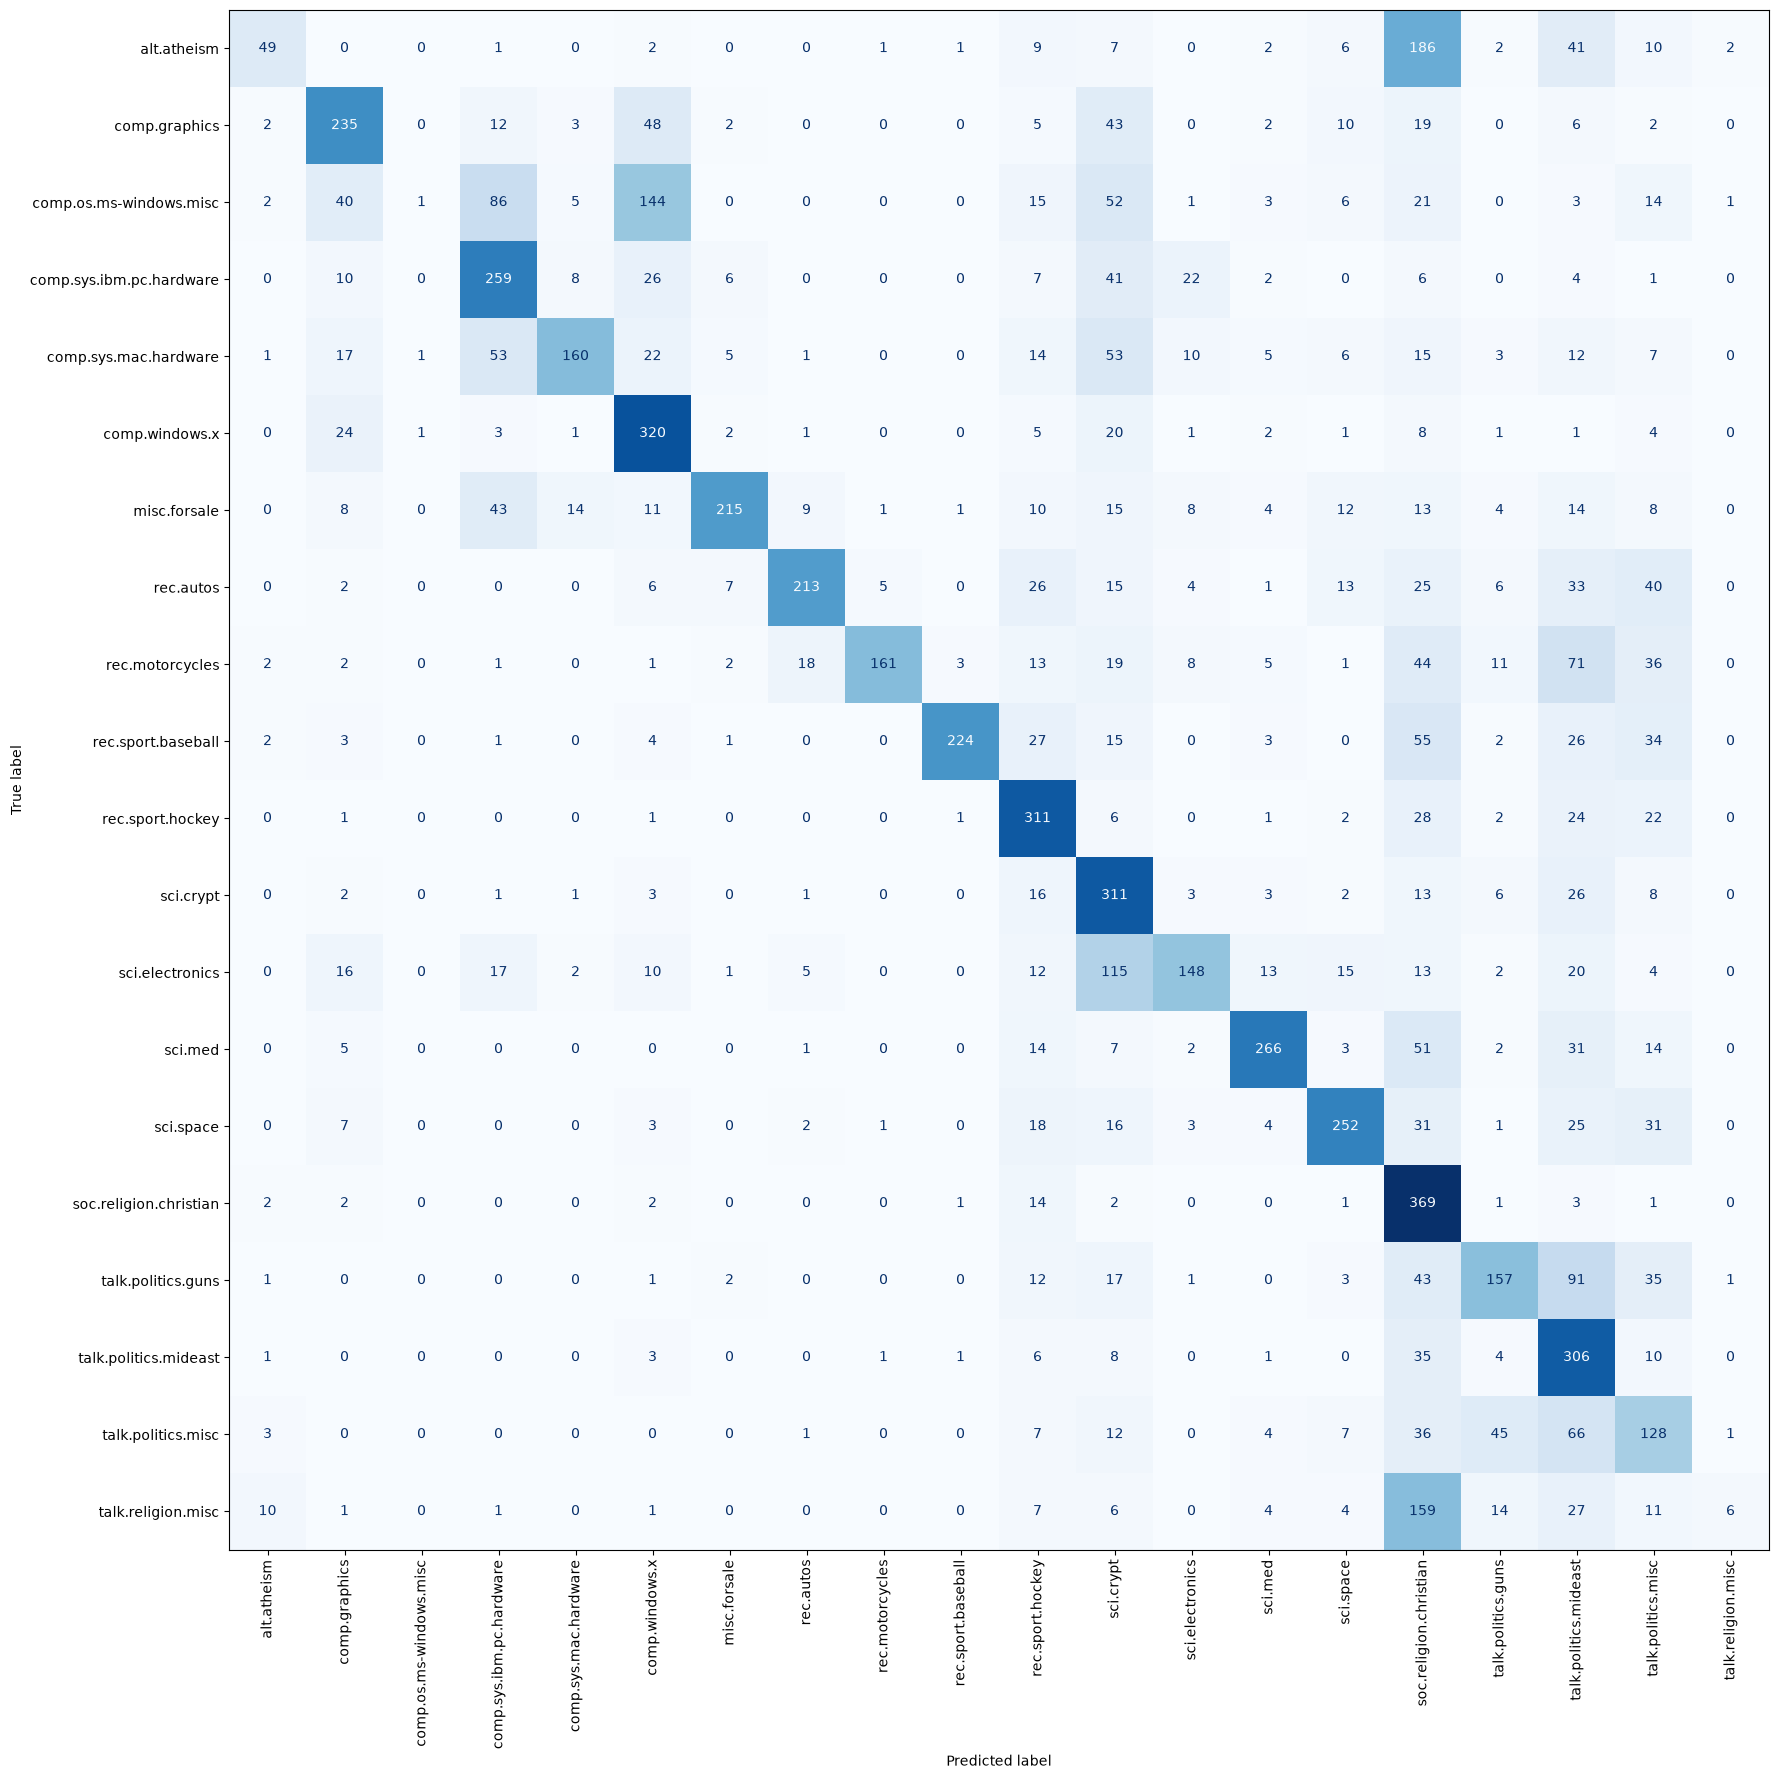

In [26]:
plt.rcParams["figure.figsize"] = (20,20)
ConfusionMatrixDisplay.from_estimator(nb, x, text_valid['target'],cmap='Blues',
                                      display_labels=text_train['target_names'],
                                    xticks_rotation='vertical',colorbar=False)

plt.show()

## NLP Version 2
Along came RNNs.  Now we can use position and Neural Networks to improve upon our example.  This was the style from 2010-2017.  This is a basic example.  RNNs had fancy attention mechanisms (more on that in a bit), but the basic concept was put in a token to an RNN and compute.  Later on we got word embeddings which you see as the first layer in the network.  This is a late 2016/2017 example with an "Advanced" RNN -- The GRU (similar to an LSTM) and word embeddings.

So make some sequences--not that the `make_seq` function is defined in section 1.0


In [27]:
X_train['sequence'] = X_train['message'].apply(make_seq)
x_valid['sequence'] = x_valid['message'].apply(make_seq)

### Sidebar
I went on a tangent to figure out in the histogram below why there was a "spike" of short sequences.  It was just emplty replies.

In [28]:
# a  little outta place, I wondered what all these short sequences were
X_train[X_train['message'].apply(len)==1]

,message,class,sequence
252,,0,"[2, 2]"
599,,2,"[2, 2]"
800,,7,"[2, 2]"
929,,3,"[2, 2]"
1204,,2,"[2, 2]"
2308,,18,"[2, 2]"
2368,,7,"[2, 2]"
2500,,16,"[2, 2]"
2984,,15,"[2, 2]"
3753,,12,"[2, 2]"


## Sequence Length
One of the first problems is all sequences must be the same length.  So we need to figure out an optimal length.  We will pad entries that are too short and truncate things that are too long.  Generally as a rule of thumb, look at your data and pick a number that incorporates 90-99% of your data.  You always have some VERY long sequences.

(array([228.,  60.,  27.,  33.,  25.,  30.,  36.,  42.,  39.,  31.,  42.,
         30.,  45.,  49.,  67.,  47.,  56.,  52.,  42.,  50.,  65.,  53.,
         59.,  61.,  70.,  67.,  65.,  57.,  64.,  77.,  78.,  72.,  77.,
         65.,  78.,  81.,  69.,  70.,  76.,  72.,  66.,  79.,  94.,  68.,
         72.,  72.,  70.,  69.,  78.,  72.,  54.,  74.,  86.,  62.,  65.,
         76.,  61.,  71.,  67.,  50.,  60.,  71.,  48.,  73.,  58.,  47.,
         64.,  67.,  70.,  55.,  68.,  54.,  56.,  49.,  56.,  43.,  52.,
         40.,  49.,  46.,  44.,  51.,  47.,  38.,  41.,  64.,  55.,  47.,
         46.,  50.,  44.,  46.,  46.,  49.,  43.,  30.,  57.,  39.,  51.,
         28.,  49.,  34.,  34.,  28.,  41.,  41.,  40.,  34.,  44.,  47.,
         45.,  32.,  39.,  41.,  28.,  40.,  39.,  40.,  32.,  33.,  36.,
         26.,  27.,  36.,  35.,  34.,  31.,  26.,  39.,  29.,  35.,  36.,
         32.,  23.,  36.,  35.,  22.,  28.,  25.,  39.,  35.,  40.,  26.,
         31.,  36.,  24.,  24.,  25., 

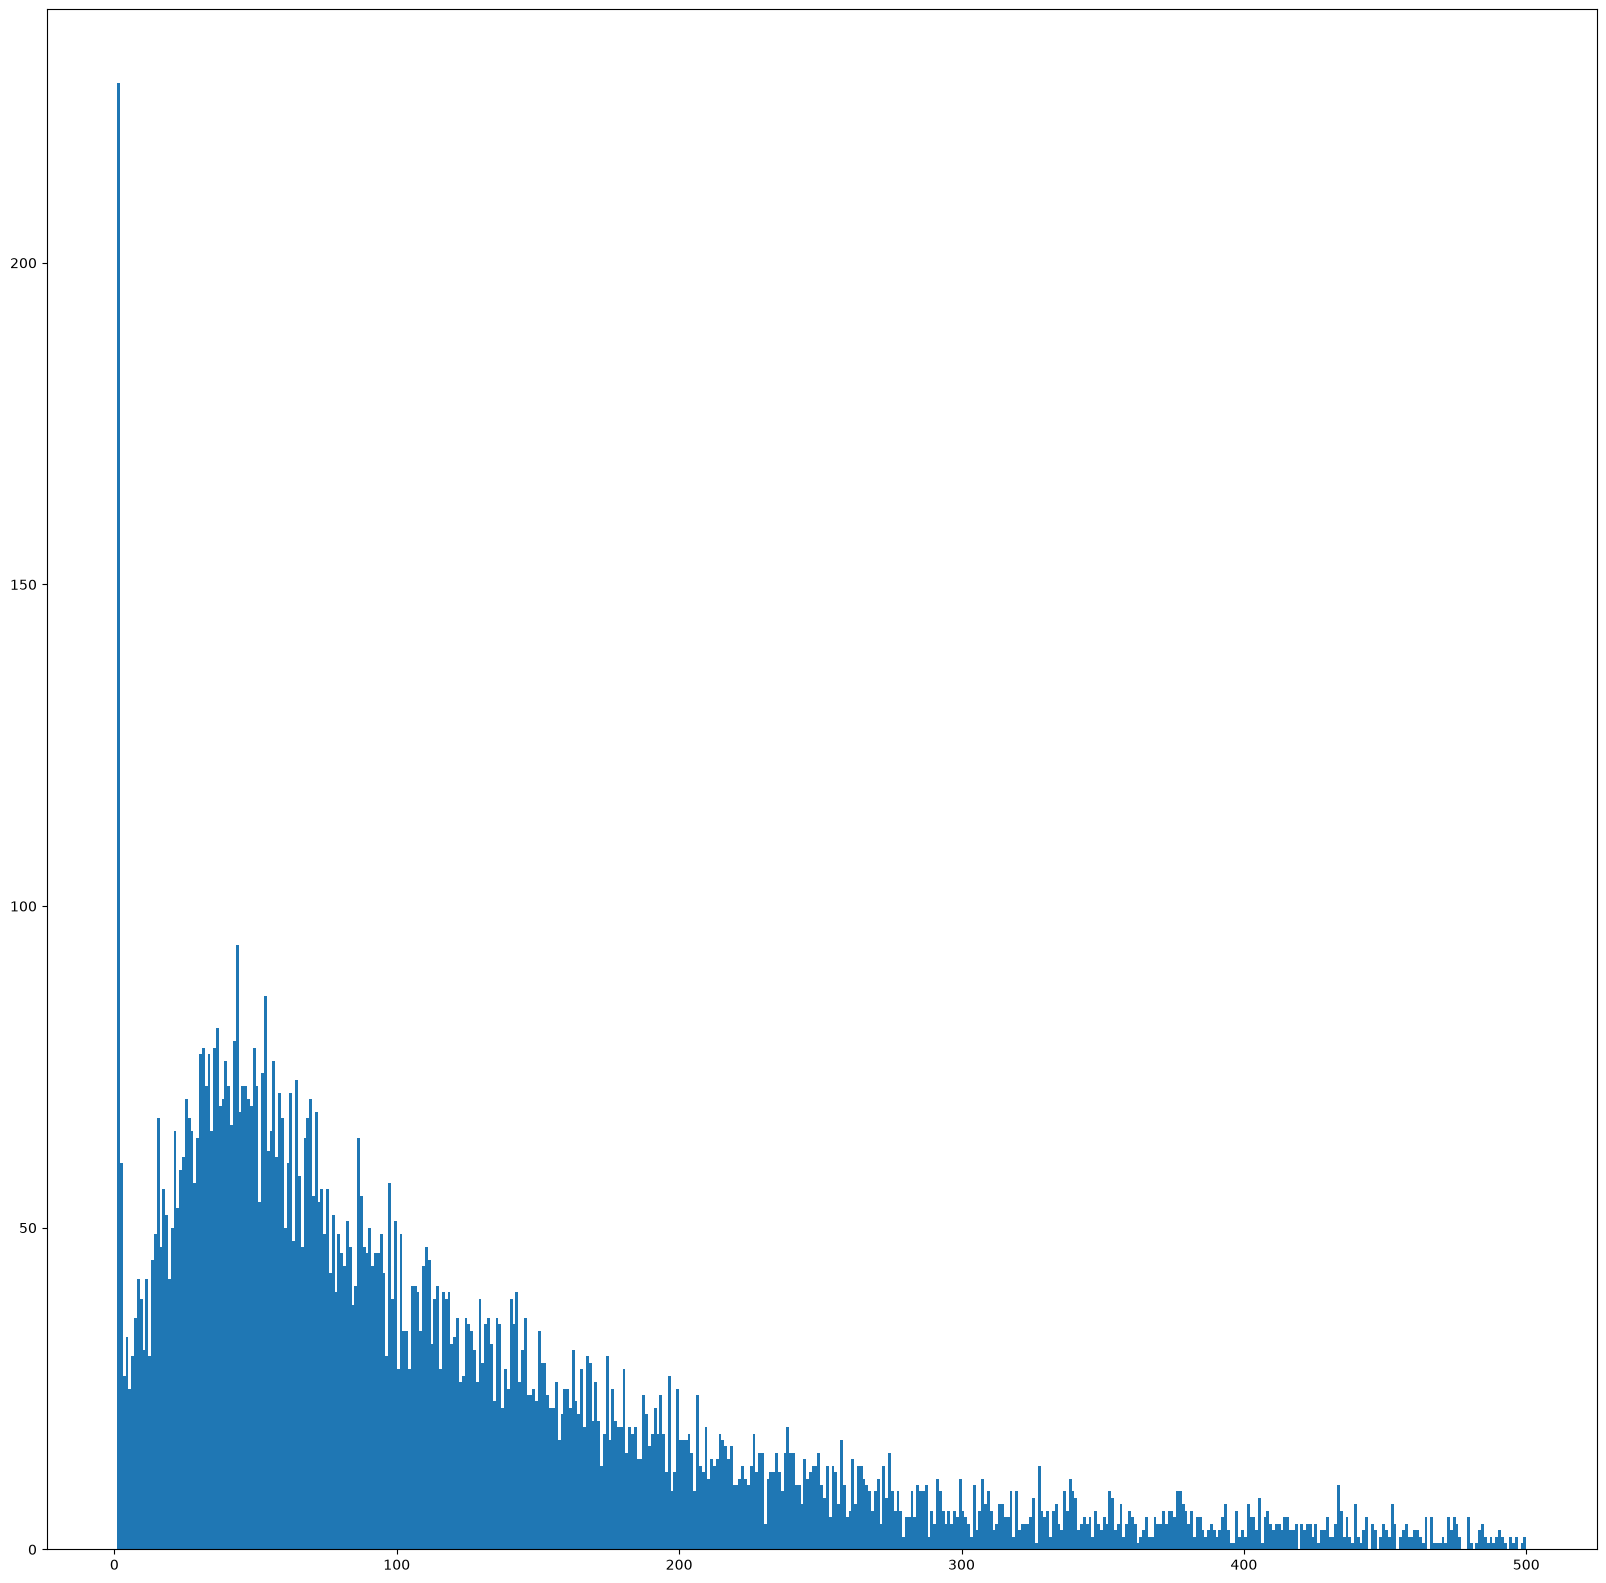

In [29]:
# a histogram!
# Notice that spike around 0--thats what I was exploring above!
my_bins = np.linspace(1,500,500)
plt.hist(X_train['sequence'].apply(len),bins=my_bins)

How is class balance?  Not too bad

In [30]:
X_train['class'].value_counts()

class
10    600
15    599
8     598
9     597
11    595
7     594
13    594
14    593
5     593
2     591
12    591
3     590
6     585
1     584
4     578
17    564
16    546
0     480
18    465
19    377
Name: count, dtype: int64

Find my sequence length

I tried 99, 95, and 90--the sequences were really long, so I did 90.

In [31]:
print(np.quantile(X_train['sequence'].apply(len),.99))
print(np.quantile(X_train['sequence'].apply(len),.95))
print(np.quantile(X_train['sequence'].apply(len),.90))

2592.700000000008
721.0500000000011
401.0


Pad them to 400 or chop down to 400.  Default pad is 0 which I used, so no need to tell it what the pad number is

In [32]:
max_length = 400 # not precisily 90th percentile, but we love even numbers
# default pad is 0, not everyone uses default--its a hidden GOTCHA!
# But I used default
X_train_data = sequence.pad_sequences(X_train['sequence'], maxlen=max_length)
x_valid_data = sequence.pad_sequences(x_valid['sequence'], maxlen=max_length)

## RNN
This has evolved over the years, but this works in modern Tensorflow.  We tell the network the length of our sequence, then create our embedding layer that will contain our word vectors.  Yes I made the vector size 101.  On purpose.  The point is we use these bumber and while they are somewhat arbitrary, you dont HAVE to use even numbers of powers of 2.   You can swap out GRU for LSTM or even Vanilla RNN (Vanilla isn't optimized for GPUs, so its SLOOOOW).  GRU and LSTM perform about the same--LSTM uses 25% more parameters as it has 4 "layers" inside its block, while GRU essentially has 3.  The RNN is just a Dense layer that takes in a word vector that is appended with the previous sequence outputs.  So a GRU(100) has 100 outputs, but the input size is 201! (101 for our vector, 100 for previous output!).  The embedding layer storers 5000 word vectors (if we want more we can change it!) but when we encoded we used the top 5000 words.  

In [46]:
from tensorflow.keras import Input
# create the model
es = EarlyStopping(patience=5, restore_best_weights=True)
vector_size = 101 #even numbers are for losers!
model = Sequential()
model.add(Input(shape=(max_length,)))  # Keras 3: input_length on Embedding is gone, declare the input instead
model.add(Embedding(5000, vector_size))
model.add(GRU(100)) #I started with LSTM for speed, but GRU gave better results.  No Free Lunch!
model.add(Dropout(0.30)) #this thing overtrains hard, so Dropout is your regularization in NN
model.add(Dense(500,activation='relu'))
model.add(Dropout(0.30))
model.add(Dense(20, activation='softmax'))
#I threw in the top k accuracy to show that while results aren't great, it is getting things mostly right
# annd just confusing similar tasks.
model.compile(loss='sparse_categorical_crossentropy', optimizer='rmsprop', metrics=['accuracy','sparse_top_k_categorical_accuracy'])
model.summary()
model.fit(X_train_data, X_train['class'], validation_data=(x_valid_data, x_valid['class']),
          epochs=300, batch_size=64, callbacks=[es])

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 400, 101)       │       505,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 100)            │        60,900 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 500)            │        50,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 500)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 20)             │        10,020 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 626,420 (2.39 MB)

 Trainable params: 626,420 (2.39 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/300
177/177 ━━━━━━━━━━━━━━━━━━━━ 12s 59ms/step - accuracy: 0.0614 - loss: 2.9870 - sparse_top_k_categorical_accuracy: 0.2805 - val_accuracy: 0.0724 - val_loss: 2.9749 - val_sparse_top_k_categorical_accuracy: 0.3145
Epoch 2/300
177/177 ━━━━━━━━━━━━━━━━━━━━ 13s 74ms/step - accuracy: 0.0964 - loss: 2.9026 - sparse_top_k_categorical_accuracy: 0.3652 - val_accuracy: 0.1074 - val_loss: 2.8246 - val_sparse_top_k_categorical_accuracy: 0.3952
Epoch 3/300
177/177 ━━━━━━━━━━━━━━━━━━━━ 9s 52ms/step - accuracy: 0.1236 - loss: 2.7178 - sparse_top_k_categorical_accuracy: 0.4754 - val_accuracy: 0.1305 - val_loss: 2.6230 - val_sparse_top_k_categorical_accuracy: 0.5054
Epoch 4/300
177/177 ━━━━━━━━━━━━━━━━━━━━ 9s 51ms/step - accuracy: 0.1575 - loss: 2.5560 - sparse_top_k_categorical_accuracy: 0.5546 - val_accuracy: 0.1460 - val_loss: 2.6431 - val_sparse_top_k_categorical_accuracy: 0.5191
Epoch 5/300
177/177 ━━━━━━━━━━━━━━━━━━━━ 13s 74ms/step - accuracy: 0.2070 - loss: 2.3973 - sparse_top_k_catego

In [47]:
preds = np.argmax(model.predict(x_valid_data),axis=1)
results['GRU (learned embeddings)'] = accuracy_score(x_valid['class'], preds)

236/236 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step


In [33]:
preds

array([14,  1,  2, ..., 14,  6, 15], shape=(7532,))

In [52]:
v = confusion_matrix(x_valid['class'], preds, normalize='true')

In [53]:
plot = ConfusionMatrixDisplay(v,display_labels=text_train['target_names'])

Make it big and make it readable.

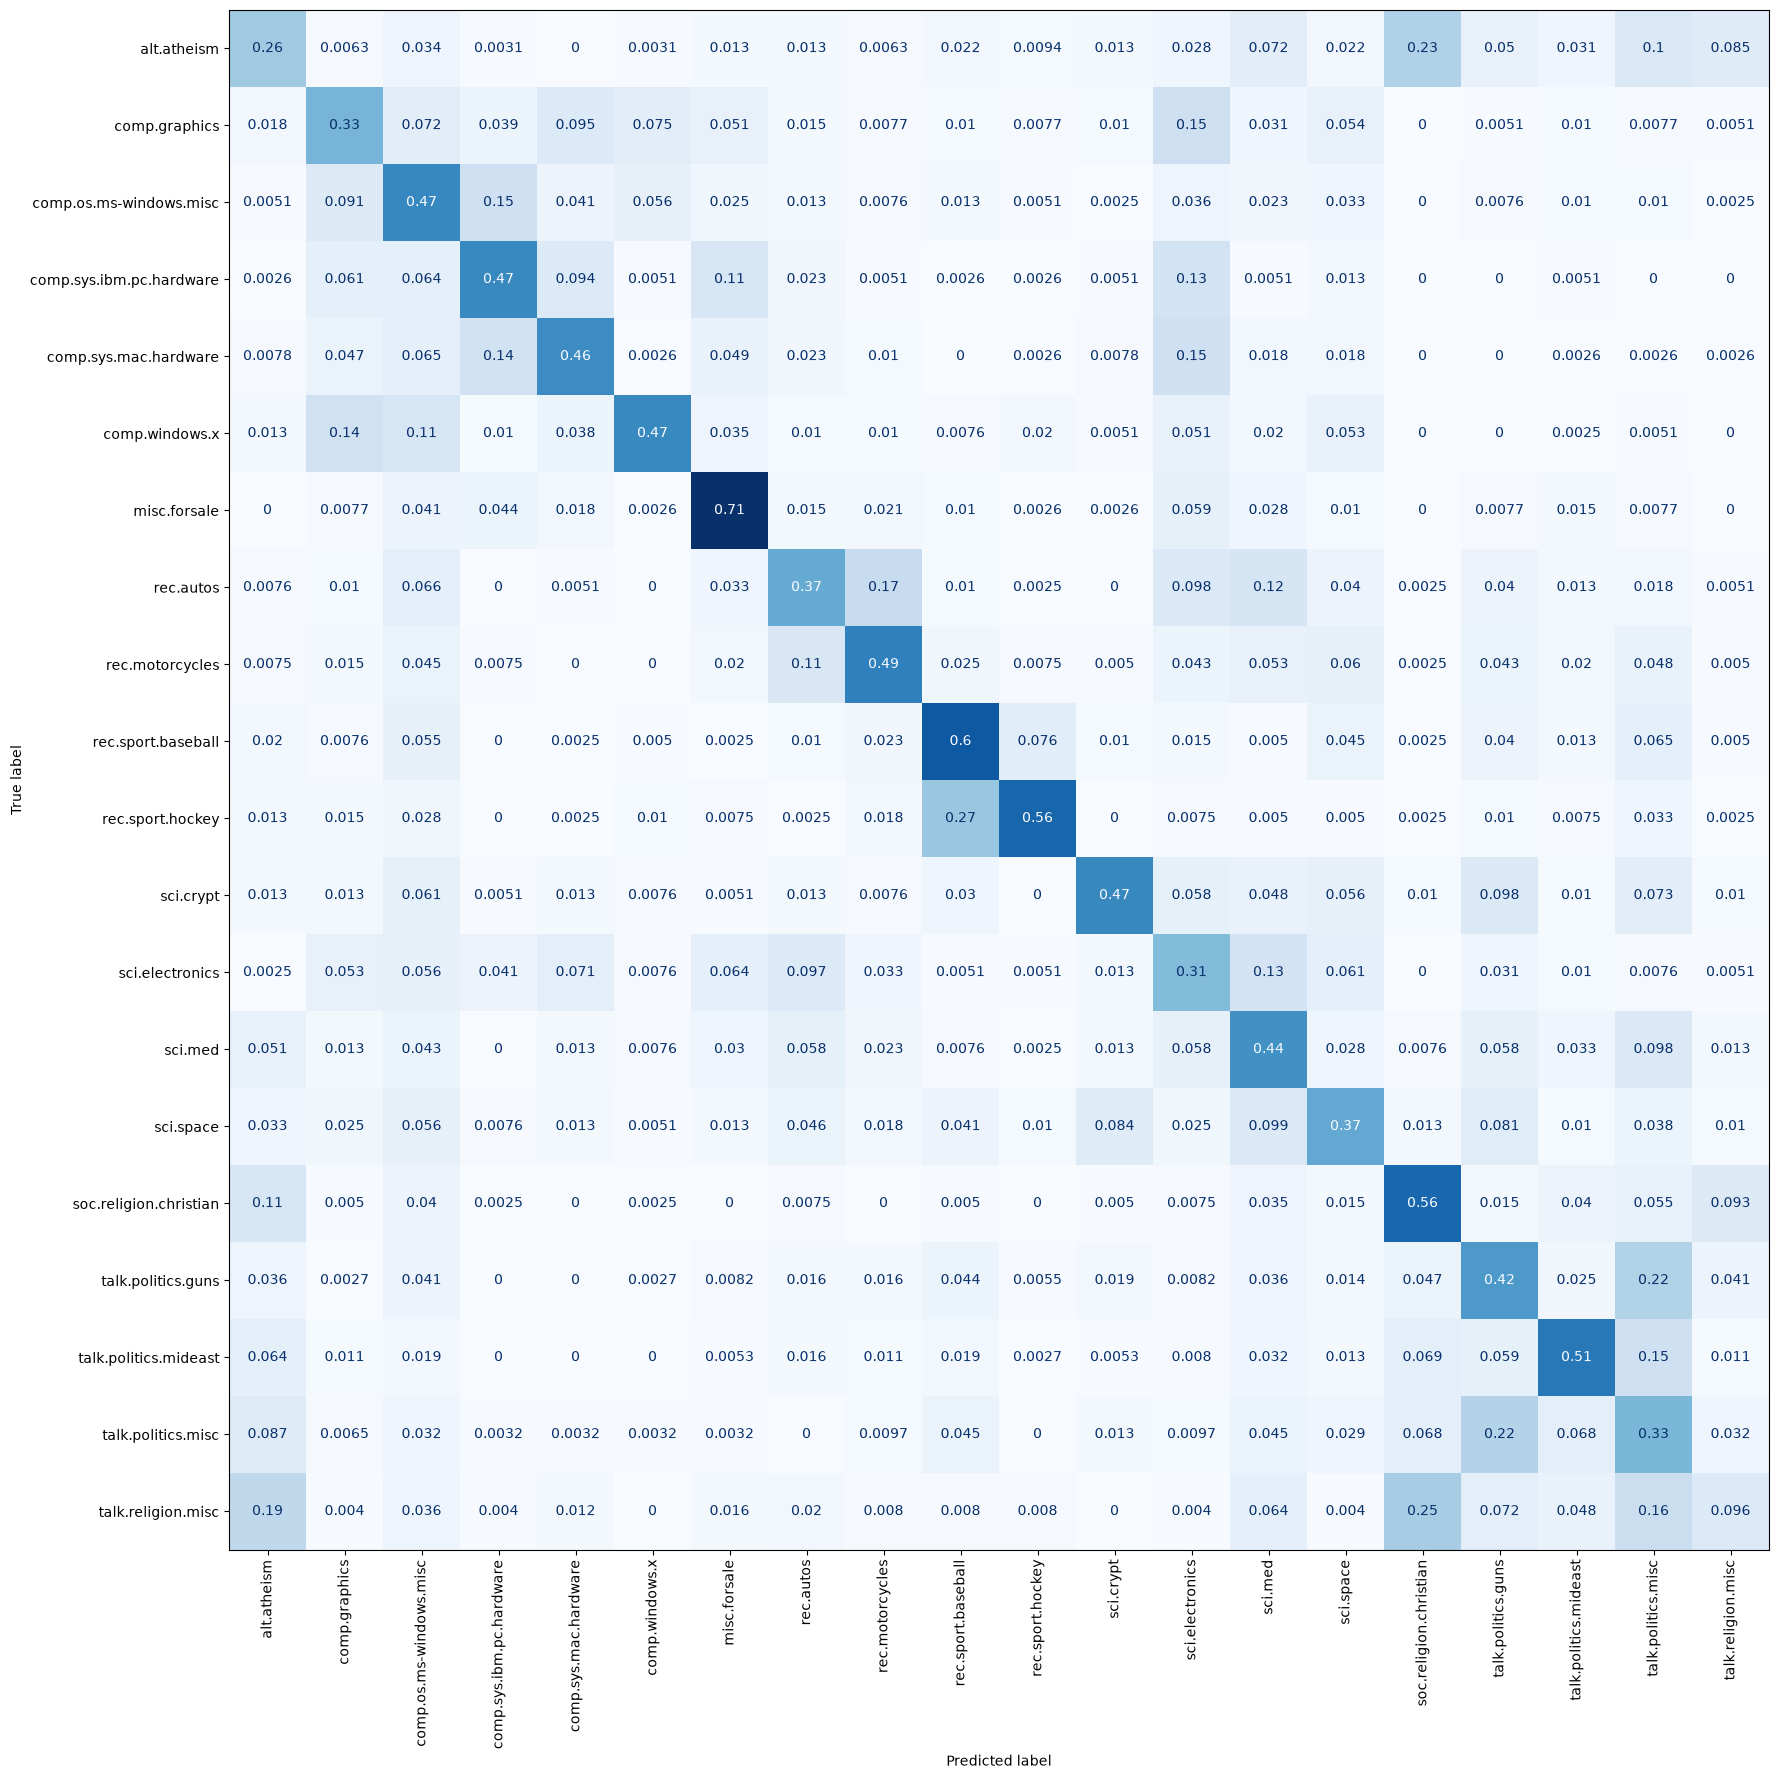

In [55]:
plt.rcParams["figure.figsize"] = (20,20)
plot.plot(xticks_rotation='vertical',cmap='Blues', colorbar=False)
plt.show()

A small helper so each of the remaining models gets the same treatment: record accuracy, then draw the big confusion matrix.

In [34]:
def show_results(name, y_true, preds):
    acc = accuracy_score(y_true, preds)
    results[name] = acc
    print(f"{name}: test accuracy = {acc:.3f}")
    v = confusion_matrix(y_true, preds, normalize='true')
    plot = ConfusionMatrixDisplay(v, display_labels=text_train['target_names'])
    plt.rcParams["figure.figsize"] = (20,20)
    plot.plot(xticks_rotation='vertical', cmap='Blues')
    plt.title(name)
    plt.show()

### NLP Version 3
Transformers came along and changed everything.  This is two examples of Early Transformers--the Universal Sentence Encoder and BERT.  BERT was a big breakthrough (one of several) that restored bi-direction sequences (One of the tricks of the RNN was to run the sequence input BACKWARDS as well as FORWARDS and combine the results.  Attention is all you need started the craze, but BERT allowed us transfer learning in NLP

## Transformer Flex
Previous was the standard RNN style processing.  Not bad, but not great.  Now we get to modern transfer learning and Transformer based NLP.  The Universal Sentence Encode takes a series of text and makes a sentence vector.  It combines all of your words into a representation that has 512 dense numbers.

From there we can then pass those numbers as inputs to dense layers.  In essence, USE acts an a feature generator for us, and the result despite severely abusing the term 'sentence' is greatly improved.

Notice also this takes text in directly, so i don't have to worry about sequences or mapping words to numbers.
Very nice!  Basically we are using the USE as a encoder that transforms our "post" into a vector.

Note: Tensorflow-hub was Hugging-Face before Hugging-Face.  Ahh the good old days of 2018!

Paper:
https://arxiv.org/pdf/1803.11175.pdf

### Do note the first time this is run, the model is downloaded--there models are in the 100+ MB range so it can take a bit

> **2026 update: what broke and how this is fixed.** TensorFlow 2.16+ ships **Keras 3**, and `hub.KerasLayer` is a **Keras 2** layer.
> That is where the `'KerasTensor' object is not callable` and `A KerasTensor is symbolic` errors came from.
> The fix is to skip `KerasLayer`: load USE with `hub.load()`, which returns a plain callable, and turn every post into its 512 numbers **once, up front**.
> The original never trained USE (`KerasLayer` defaults to `trainable=False`), so this is the same model. It is also much faster,
> because we no longer re-encode 11,000 posts every epoch, and the classifier on top is plain Keras 3.
>
> If you *do* want to fine-tune USE inside Keras, you need the Keras 2 compatibility shim:
> `pip install tf-keras`, run `import os; os.environ["TF_USE_LEGACY_KERAS"] = "1"` **before** importing TensorFlow (restart the kernel),
> then build the model with `tf_keras` instead of `keras`. That pins you to a legacy API, so the frozen approach below is the better path.

In [35]:
import tensorflow as tf
import tensorflow_hub as hub
from tensorflow.keras import Input

# tfhub.dev links now redirect to Kaggle Models; hub.load follows the redirect.
module_url = "https://tfhub.dev/google/universal-sentence-encoder/4"
use = hub.load(module_url)
print("module %s loaded" % module_url)

def use_embed(texts, batch_size=256):
    """Run text through USE in batches (all 11k at once is the 3-6 GB allocation warning)."""
    texts = list(texts)
    chunks = [use(tf.constant(texts[i:i + batch_size])).numpy()
              for i in range(0, len(texts), batch_size)]
    return np.vstack(chunks)

print(use_embed(["This is is a test"]).shape)  # one 'sentence' -> 512 numbers
use_train = use_embed(X_train['message'])
use_valid = use_embed(x_valid['message'])
use_train.shape, use_valid.shape

/home/rdslater/projects/llm-redo/.venv/lib/python3.12/site-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


module https://tfhub.dev/google/universal-sentence-encoder/4 loaded
(1, 512)


((11314, 512), (7532, 512))

In [36]:
# Same head as before: dense layers on top of the 512 USE features
es = EarlyStopping(patience=5, restore_best_weights=True)
use_model = Sequential([
    Input(shape=(512,)),
    Dense(512, activation='relu'),
    Dense(256, activation='relu'),
    Dense(20, activation='softmax'),
])
use_model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy','sparse_top_k_categorical_accuracy'])
use_model.summary()
use_model.fit(use_train, X_train['class'], validation_data=(use_valid, x_valid['class']),
          epochs=300, batch_size=64, callbacks=[es])

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 20)             │         5,140 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 399,124 (1.52 MB)

 Trainable params: 399,124 (1.52 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/300


... (2 outputs left out)

I0000 00:00:1795492927.820263 1564216 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


170/177 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5755 - loss: 1.4842 - sparse_top_k_categorical_accuracy: 0.8586

I0000 00:00:1795492928.706223 1564218 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_8069__.19


177/177 ━━━━━━━━━━━━━━━━━━━━ 6s 23ms/step - accuracy: 0.5798 - loss: 1.4657 - sparse_top_k_categorical_accuracy: 0.8612 - val_accuracy: 0.6540 - val_loss: 1.1159 - val_sparse_top_k_categorical_accuracy: 0.9065
Epoch 2/300
177/177 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7062 - loss: 0.9179 - sparse_top_k_categorical_accuracy: 0.9328 - val_accuracy: 0.6560 - val_loss: 1.0958 - val_sparse_top_k_categorical_accuracy: 0.9105
Epoch 3/300
177/177 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7320 - loss: 0.8243 - sparse_top_k_categorical_accuracy: 0.9436 - val_accuracy: 0.6552 - val_loss: 1.1064 - val_sparse_top_k_categorical_accuracy: 0.9096
Epoch 4/300
177/177 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7538 - loss: 0.7557 - sparse_top_k_categorical_accuracy: 0.9523 - val_accuracy: 0.6585 - val_loss: 1.1172 - val_sparse_top_k_categorical_accuracy: 0.9099
Epoch 5/300
177/177 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7759 - loss: 0.6902 - sparse_top_k_categorical_accuracy: 0.9

236/236 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Universal Sentence Encoder + dense (TF): test accuracy = 0.656


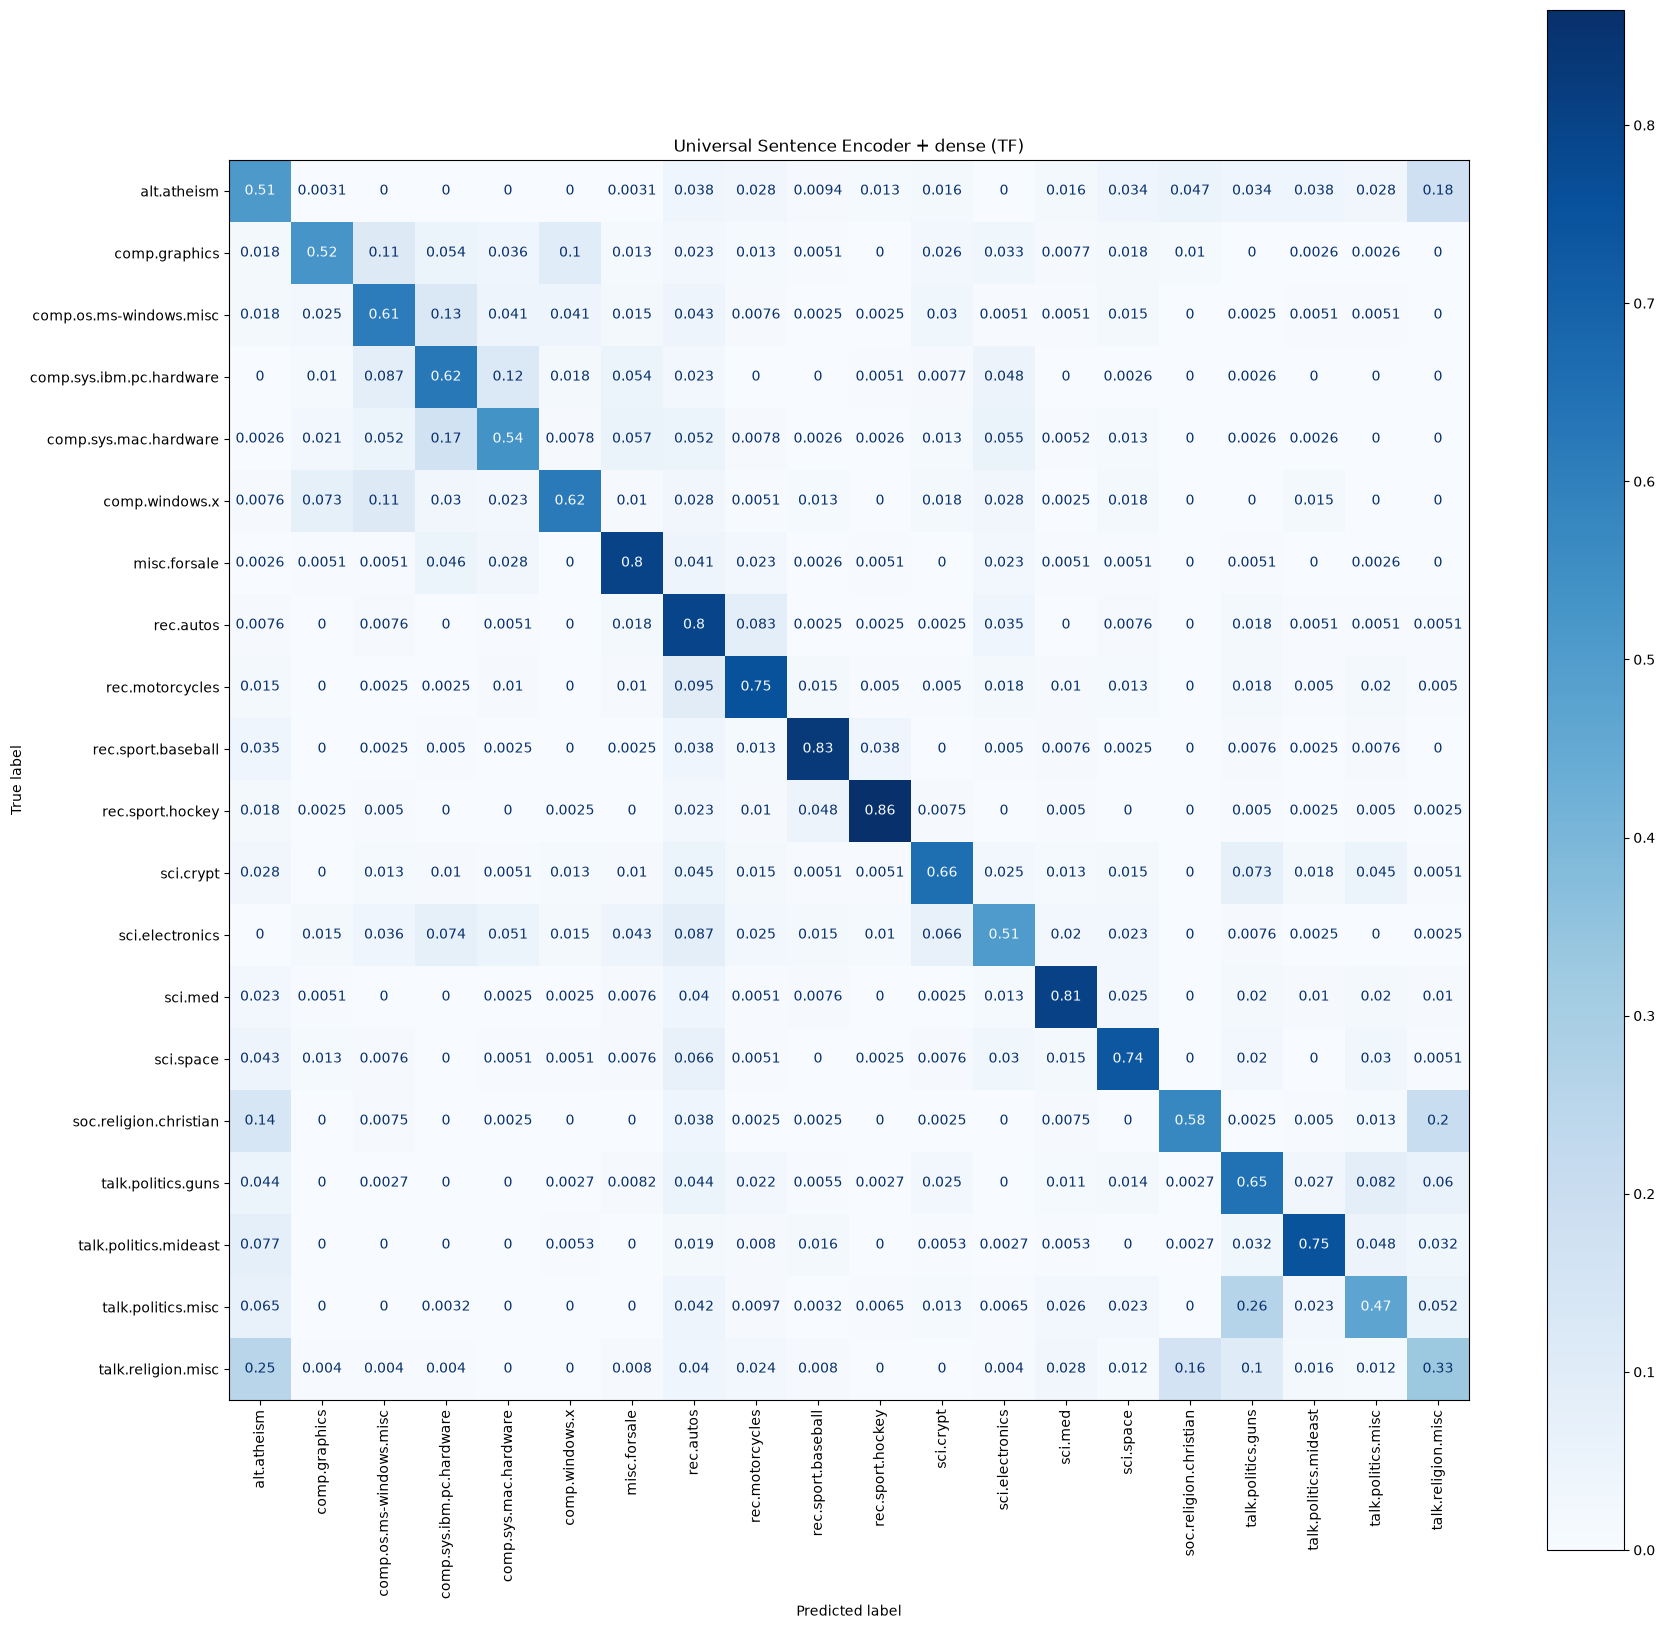

In [37]:
preds = np.argmax(use_model.predict(use_valid), axis=1)
show_results('Universal Sentence Encoder + dense (TF)', x_valid['class'], preds)

## Switching to PyTorch

From here on everything uses **PyTorch + Hugging Face `transformers`**. Most new NLP models are released there first,
and the tokenizer is plain Python, so there's no `tensorflow_text` version to keep in lockstep with TensorFlow.

Two Keras-to-PyTorch differences show up in the code:
* You write the training loop yourself instead of calling `model.fit`. It is more typing, but you can see every step.
* `nn.CrossEntropyLoss` expects raw scores (logits), so the last layer has **no softmax**. `argmax` gives the same answer either way.

On WSL, check that `torch.cuda.is_available()` is `True` (the next cell prints the device). The default `pip install torch` on Linux
already includes CUDA. Only the NVIDIA Windows driver is needed; don't install a separate Linux driver inside WSL.

`train_head` below is the PyTorch version of the dense-layers-plus-early-stopping head used for USE. We'll reuse it.

In [38]:
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

device = 'cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu'
print('using', device)

def train_head(X_tr, y_tr, X_va, y_va, hidden=512, epochs=300, patience=5, lr=1e-3, batch_size=64):
    """Dense head on frozen features, with early stopping on validation loss. Returns (head, validation predictions)."""
    X_tr, X_va = torch.tensor(X_tr, dtype=torch.float32), torch.tensor(X_va, dtype=torch.float32)
    y_tr, y_va = torch.tensor(np.asarray(y_tr)), torch.tensor(np.asarray(y_va))
    head = nn.Sequential(
        nn.Linear(X_tr.shape[1], hidden), nn.ReLU(), nn.Dropout(0.3),
        nn.Linear(hidden, 20),            # logits -- CrossEntropyLoss does the softmax
    ).to(device)
    opt = torch.optim.Adam(head.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    loader = DataLoader(TensorDataset(X_tr, y_tr), batch_size=batch_size, shuffle=True)
    best_loss, best_state, bad_epochs = float('inf'), None, 0
    for epoch in range(epochs):
        head.train()
        for xb, yb in loader:
            opt.zero_grad()
            loss = loss_fn(head(xb.to(device)), yb.to(device))
            loss.backward()
            opt.step()
        head.eval()
        with torch.no_grad():
            logits = head(X_va.to(device)).cpu()
        val_loss = loss_fn(logits, y_va).item()
        val_acc = (logits.argmax(1) == y_va).float().mean().item()
        print(f'epoch {epoch+1:3d}  val_loss {val_loss:.4f}  val_acc {val_acc:.4f}')
        if val_loss < best_loss:
            best_loss, bad_epochs = val_loss, 0
            best_state = {k: v.detach().clone() for k, v in head.state_dict().items()}
        else:
            bad_epochs += 1
            if bad_epochs >= patience:
                break
    head.load_state_dict(best_state)   # same as restore_best_weights=True
    head.eval()
    with torch.no_grad():
        return head, head(X_va.to(device)).argmax(1).cpu().numpy()

using cuda


### USE in PyTorch (optional)
Google never released USE for PyTorch. `distiluse-base-multilingual-cased-v2` is a smaller model trained to copy multilingual USE's 512-number output,
so it is the nearest drop-in replacement. `sentence-transformers` provides the "text in, vector out" step that `hub.load` did above.

modules.json:   0%|          | 0.00/341 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/2.46k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/610 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  539MB            

... (9 outputs left out)

2_Dense/model.safetensors: downloading bytes:           |  0.00B            

Batches:   0%|          | 0/177 [00:00<?, ?it/s]

Batches:   0%|          | 0/118 [00:00<?, ?it/s]

epoch   1  val_loss 1.2811  val_acc 0.6236
epoch   2  val_loss 1.1349  val_acc 0.6468
epoch   3  val_loss 1.1111  val_acc 0.6522
epoch   4  val_loss 1.0982  val_acc 0.6576
epoch   5  val_loss 1.0954  val_acc 0.6583
epoch   6  val_loss 1.0996  val_acc 0.6581
epoch   7  val_loss 1.1115  val_acc 0.6572
epoch   8  val_loss 1.1148  val_acc 0.6600
epoch   9  val_loss 1.1250  val_acc 0.6568
epoch  10  val_loss 1.1358  val_acc 0.6587
Distilled USE + dense (PyTorch): test accuracy = 0.658


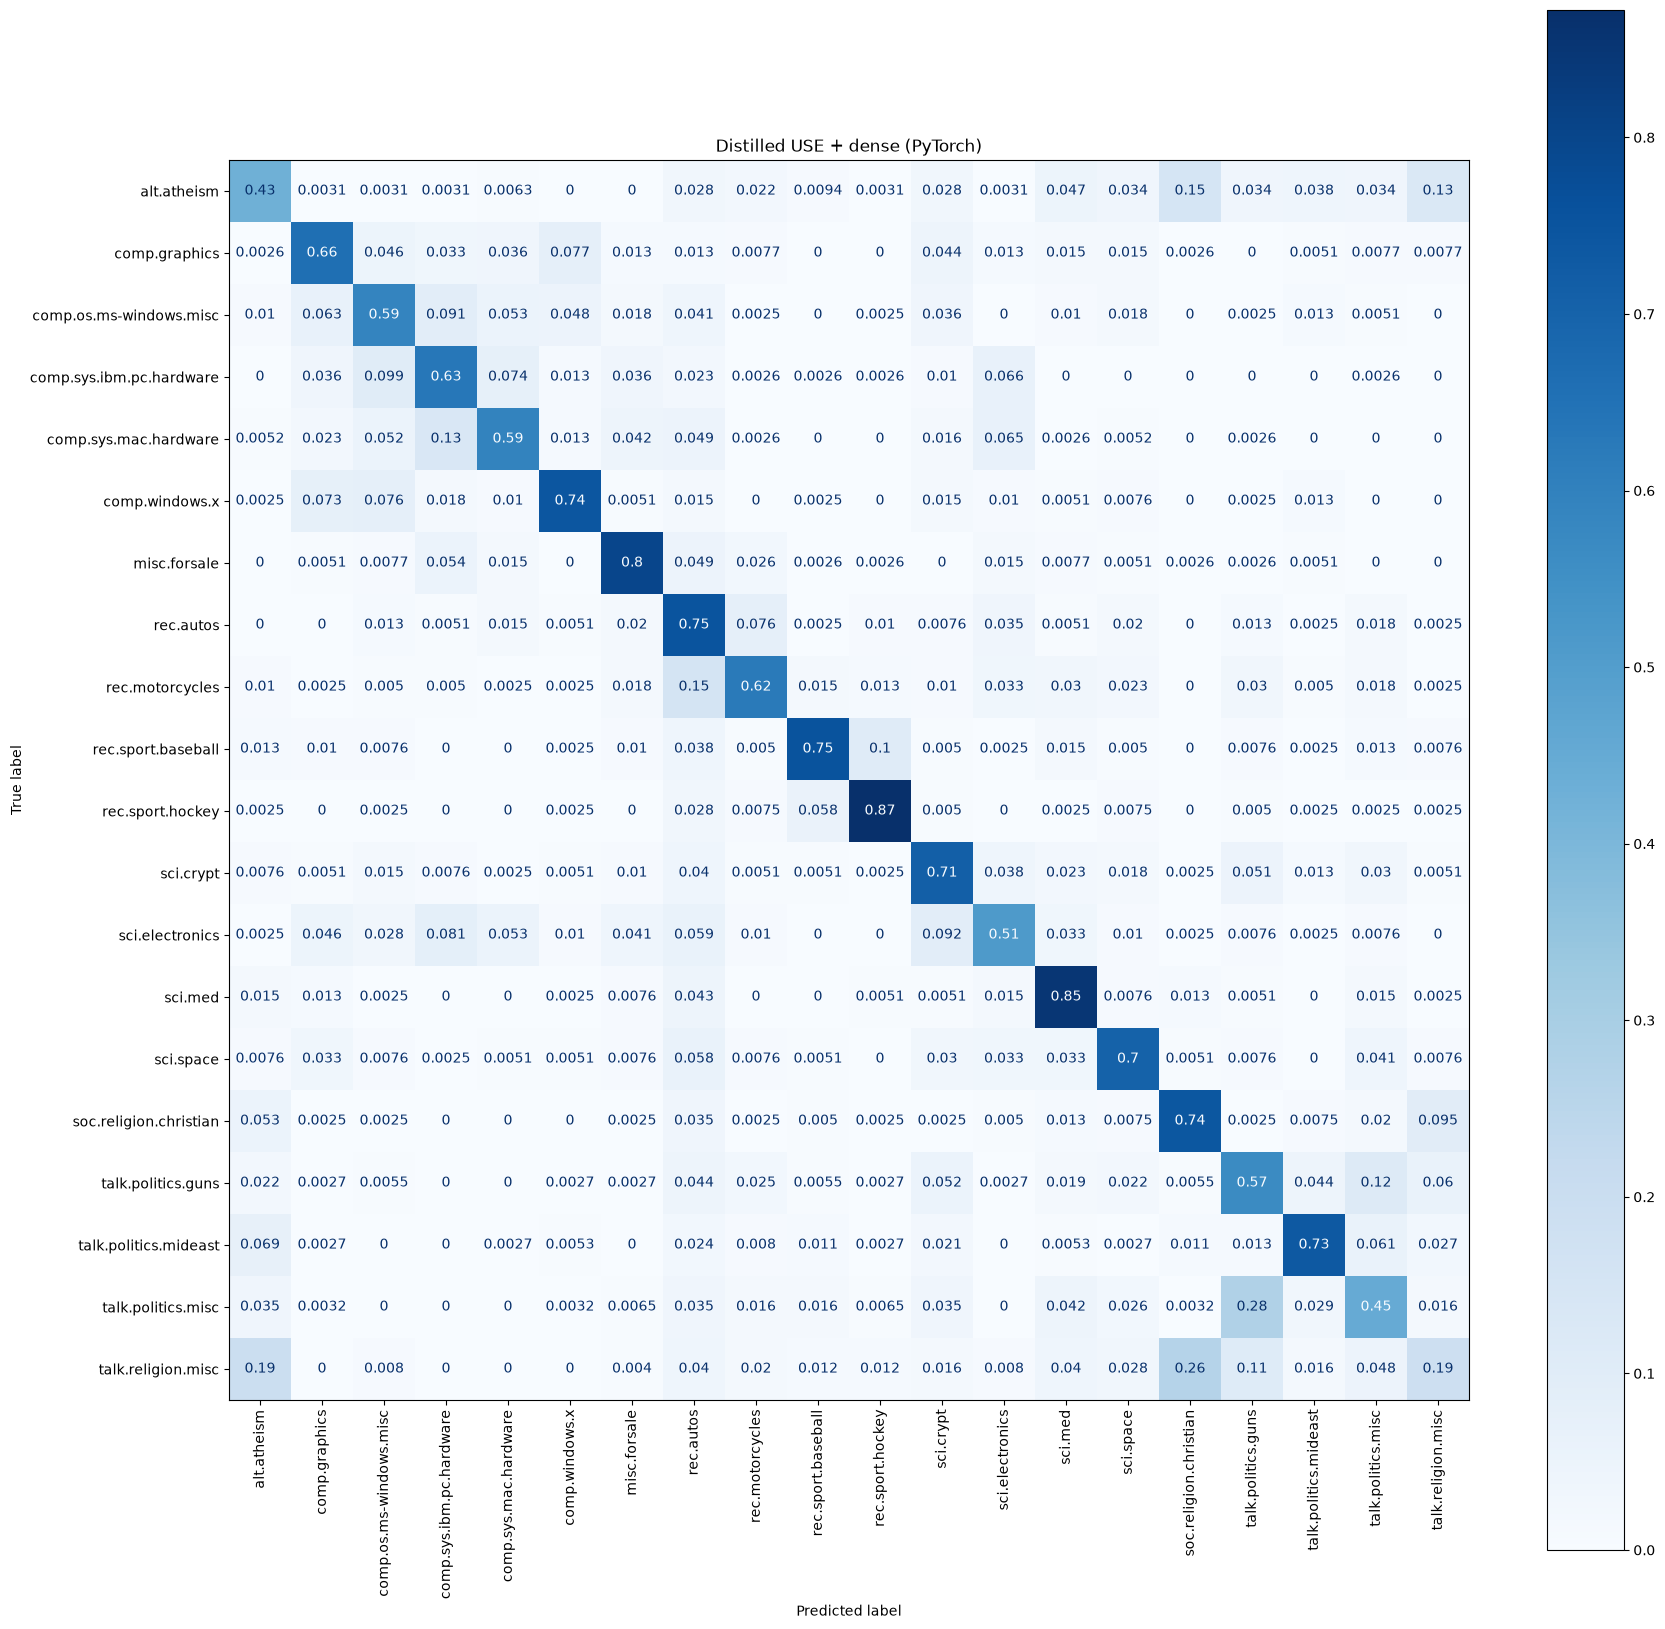

In [40]:
from sentence_transformers import SentenceTransformer

st = SentenceTransformer("sentence-transformers/distiluse-base-multilingual-cased-v2", device=device)
st_train = st.encode(X_train['message'].tolist(), batch_size=64, show_progress_bar=True)
st_valid = st.encode(x_valid['message'].tolist(), batch_size=64, show_progress_bar=True)

_, preds = train_head(st_train, X_train['class'], st_valid, x_valid['class'])
show_results('Distilled USE + dense (PyTorch)', x_valid['class'], preds)

## 2018 Flex
This was super cool in 2018, but things have evolved very rapidly.  But its an important waypoint on our journey. I have included the old Tensorflow code as a comment.  Tensorflow evolved rapidly and the adoption of LLMs gave a demand to make it 'easy'.  You used to have to tokenize and mask manually (BERT had special encodings as it was trained on two sentences).  

### Old Intro

Why not use one of the most famous models in the world?  The Bi-directional Encoding Represantive Transformer (BERT).  This shows how to download BERT and then use it as a classifier.


If you wanted individual word vectors you would use the 'sequence' output.  The pooled out is the special classifier of BERT.  Be sure to read the paper or pester your favorite NLP professor about the details as you do need the preprocessor to use the special tokenizer for BERT and recongize it has a special '\<CLS\>' token for classification that always appears first so you can always use the first (address ZERO) sequence output.  Happily this is done for us, but its always good to know the details.

The best way to try this is to use a low learning rate and set training to true.  I ran out of time preparing this, but I left the code below as an example.

https://arxiv.org/abs/1810.04805

This thing is BIG and even causes GPUs to go 'NO THANKS'

> **2026 update.** The TF Hub version broke in three ways: `hub.KerasLayer` doesn't work in Keras 3 (same as USE); `tensorflow_text` must match
> the TensorFlow version exactly and has never had native Windows builds; and its custom ops (`CaseFoldUTF8`) must be imported
> before the preprocessor loads. Here BERT runs through Hugging Face `transformers` in PyTorch instead.
> The `AutoTokenizer` does what the TF Hub preprocessor did: it adds the `[CLS]` token, splits words into WordPieces, and pads.
>
> Every TF Hub small BERT is on Hugging Face as `google/bert_uncased_L-{2,4,6,8,10,12}_H-{128,256,512,768}_A-{2,4,8,12}`,
> so the big name-to-URL dictionary is no longer needed. Swap the name to try a different size.

### OLD BERT CODE circa 2018-2020

The preprocessor was an intermediate step that did SOME of the processing for you, but before that you did the masking yourself (not really masking but sentence "markers"--it was a wild time)
```
from tensorflow.keras.layers import Input
import tensorflow_hub as hub
#import tensorflow_text as text
from tensorflow import constant,string
es = EarlyStopping(patience=2)
text_input = Input(shape=(), dtype=string)
preprocessor = hub.KerasLayer(
    "https://tfhub.dev/tensorflow/bert_en_uncased_preprocess/3")
encoder_inputs = preprocessor(text_input)
encoder = hub.KerasLayer(
    "https://tfhub.dev/tensorflow/bert_en_uncased_L-12_H-768_A-12/4",
    trainable=False)  #RIP my GPU if set to True--runs out of memory with batch size >8 if true!
outputs = encoder(encoder_inputs)
pooled_output = outputs["pooled_output"] # [batch_size, 768].
outputs = Dense(512,activation='relu')(pooled_output)
outputs = Dense(20,activation='softmax')(pooled_output)
#sequence_output = outputs["sequence_output"]  # [batch_size, seq_length, 768].
embedding_model = Model(text_input, outputs)
embedding_model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy','sparse_top_k_categorical_accuracy'])



### Step 1: BERT as a frozen feature generator
This matches the original `trainable=False` setup: BERT reads each post once, and only the small head is trained.

The TF Hub version used `pooled_output`, which is the `[CLS]` vector passed through an extra layer trained for BERT's next-sentence task.
For frozen features, **averaging all the token vectors** usually works better. Both are shown below; switch the return line to compare.

In [41]:
from transformers import AutoTokenizer, AutoModel

BERT_NAME = "google/bert_uncased_L-4_H-512_A-8"   # same small BERT the TF Hub cell picked
# BERT_NAME = "bert-base-uncased"                 # full 12-layer BERT: better, ~4x slower

tokenizer = AutoTokenizer.from_pretrained(BERT_NAME)
bert = AutoModel.from_pretrained(BERT_NAME).to(device).eval()

# Peek at what the tokenizer does -- note [CLS] at the front and the ## word pieces
print(tokenizer.tokenize("It was called a Bricklin."))

@torch.no_grad()
def bert_embed(texts, batch_size=64, max_length=256):
    texts = list(texts)
    out = []
    for i in range(0, len(texts), batch_size):
        batch = tokenizer(texts[i:i + batch_size], padding=True, truncation=True,
                          max_length=max_length, return_tensors='pt').to(device)
        hidden = bert(**batch).last_hidden_state                 # [batch, seq_len, hidden]
        mask = batch['attention_mask'].unsqueeze(-1).float()     # ignore the padding
        out.append(((hidden * mask).sum(1) / mask.sum(1)).cpu().numpy())   # mean pooling
        # out.append(hidden[:, 0].cpu().numpy())                 # raw [CLS] vector (address ZERO)
    return np.vstack(out)

bert_train = bert_embed(X_train['message'])
bert_valid = bert_embed(x_valid['message'])
bert_train.shape

Loading weights:   0%|          | 0/71 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: google/bert_uncased_L-4_H-512_A-8
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


['it', 'was', 'called', 'a', 'brick', '##lin', '.']


(11314, 512)

epoch   1  val_loss 1.5211  val_acc 0.5279
epoch   2  val_loss 1.4092  val_acc 0.5542
epoch   3  val_loss 1.3465  val_acc 0.5795
epoch   4  val_loss 1.3536  val_acc 0.5668
epoch   5  val_loss 1.3369  val_acc 0.5803
epoch   6  val_loss 1.3071  val_acc 0.5951
epoch   7  val_loss 1.3357  val_acc 0.5815
epoch   8  val_loss 1.3005  val_acc 0.5981
epoch   9  val_loss 1.3290  val_acc 0.5905
epoch  10  val_loss 1.3328  val_acc 0.5957
epoch  11  val_loss 1.3280  val_acc 0.5937
epoch  12  val_loss 1.3471  val_acc 0.5909
epoch  13  val_loss 1.3665  val_acc 0.5875
BERT frozen features + dense: test accuracy = 0.598


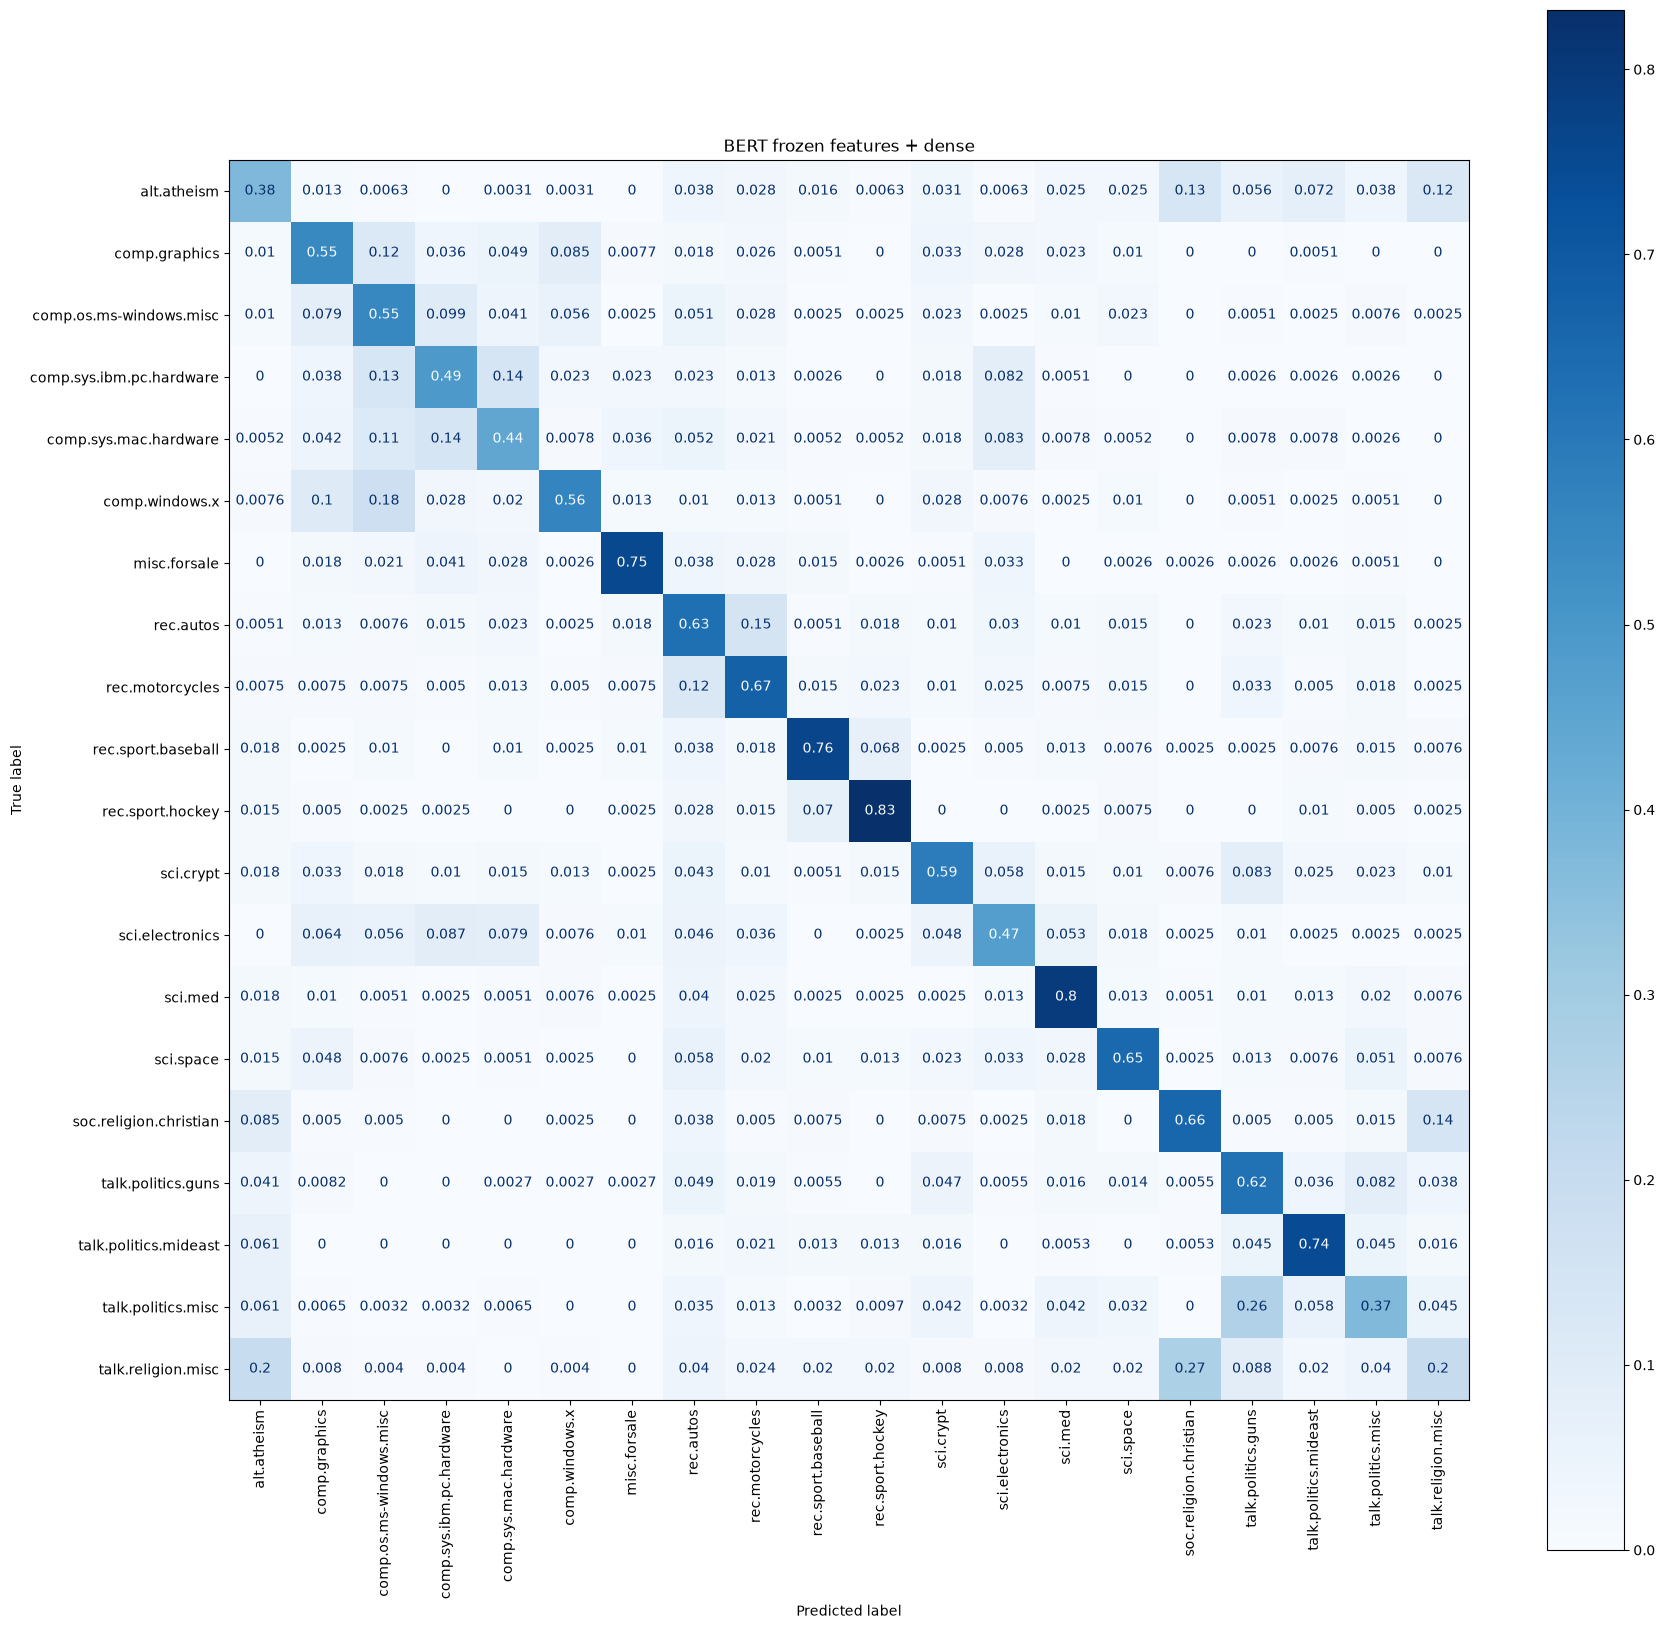

In [42]:
_, preds = train_head(bert_train, X_train['class'], bert_valid, x_valid['class'])
show_results('BERT frozen features + dense', x_valid['class'], preds)

### Step 2: Fine-tuning all of BERT ("Low Learning Rate")
This is the experiment the original didn't have time for. Every BERT weight gets updated, starting from a small learning rate.

Why the old attempt gave "very low accuracy":
* **`1e-6` is too low.** The BERT paper recommends `2e-5` to `5e-5`. Small BERTs do well with `5e-5` to `1e-4`.
* **Fine-tuning needs only 2-4 epochs**, not early stopping out of 300. Learning-rate warmup and decay help a lot.
* **Memory:** mixed precision (`autocast`) roughly halves GPU memory. Small BERT at batch 32 or bert-base at batch 16
  (both with 256 tokens) should fit on an 8 GB card like the 2070. If you run out of memory, halve `BATCH`.

`AutoModelForSequenceClassification` adds the classification layer on `[CLS]` for us.

In [43]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from tqdm.auto import tqdm

FT_NAME = "google/bert_uncased_L-4_H-512_A-8"; LR = 1e-4; BATCH = 32
# FT_NAME = "bert-base-uncased";               LR = 3e-5; BATCH = 16
MAX_LEN, EPOCHS = 256, 4

ft_tok = AutoTokenizer.from_pretrained(FT_NAME)
ft_model = AutoModelForSequenceClassification.from_pretrained(FT_NAME, num_labels=20).to(device)

def make_loader(df, shuffle):
    enc = ft_tok(df['message'].tolist(), padding='max_length', truncation=True, max_length=MAX_LEN, return_tensors='pt')
    ds = TensorDataset(enc['input_ids'], enc['attention_mask'], torch.tensor(df['class'].values))
    return DataLoader(ds, batch_size=BATCH, shuffle=shuffle)

train_loader, valid_loader = make_loader(X_train, True), make_loader(x_valid, False)

opt = torch.optim.AdamW(ft_model.parameters(), lr=LR, weight_decay=0.01)
total_steps = EPOCHS * len(train_loader)
sched = get_linear_schedule_with_warmup(opt, num_warmup_steps=int(0.1 * total_steps), num_training_steps=total_steps)
use_amp = device == 'cuda'
scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

@torch.no_grad()
def predict(model, loader):
    model.eval()
    preds = []
    for ids, mask, _ in loader:
        with torch.autocast(device_type='cuda' if use_amp else 'cpu', dtype=torch.float16, enabled=use_amp):
            logits = model(input_ids=ids.to(device), attention_mask=mask.to(device)).logits
        preds.append(logits.argmax(1).cpu().numpy())
    return np.concatenate(preds)

for epoch in range(EPOCHS):
    ft_model.train()
    running = 0.0
    for step, (ids, mask, y) in enumerate(tqdm(train_loader, desc=f'epoch {epoch+1}')):
        opt.zero_grad()
        with torch.autocast(device_type='cuda' if use_amp else 'cpu', dtype=torch.float16, enabled=use_amp):
            loss = ft_model(input_ids=ids.to(device), attention_mask=mask.to(device), labels=y.to(device)).loss
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(ft_model.parameters(), 1.0)
        scaler.step(opt)
        scaler.update()
        sched.step()
        running += loss.item()
    preds = predict(ft_model, valid_loader)
    print(f'epoch {epoch+1}: train loss {running/len(train_loader):.4f}  val acc {accuracy_score(x_valid["class"], preds):.4f}')

Loading weights:   0%|          | 0/71 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google/bert_uncased_L-4_H-512_A-8
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	thos

epoch 1:   0%|          | 0/354 [00:00<?, ?it/s]

epoch 1: train loss 1.7713  val acc 0.6490


epoch 2:   0%|          | 0/354 [00:00<?, ?it/s]

epoch 2: train loss 0.8489  val acc 0.6734


epoch 3:   0%|          | 0/354 [00:00<?, ?it/s]

epoch 3: train loss 0.5247  val acc 0.6940


epoch 4:   0%|          | 0/354 [00:00<?, ?it/s]

epoch 4: train loss 0.3375  val acc 0.6969


bert_uncased_L-4_H-512_A-8 fine-tuned: test accuracy = 0.697


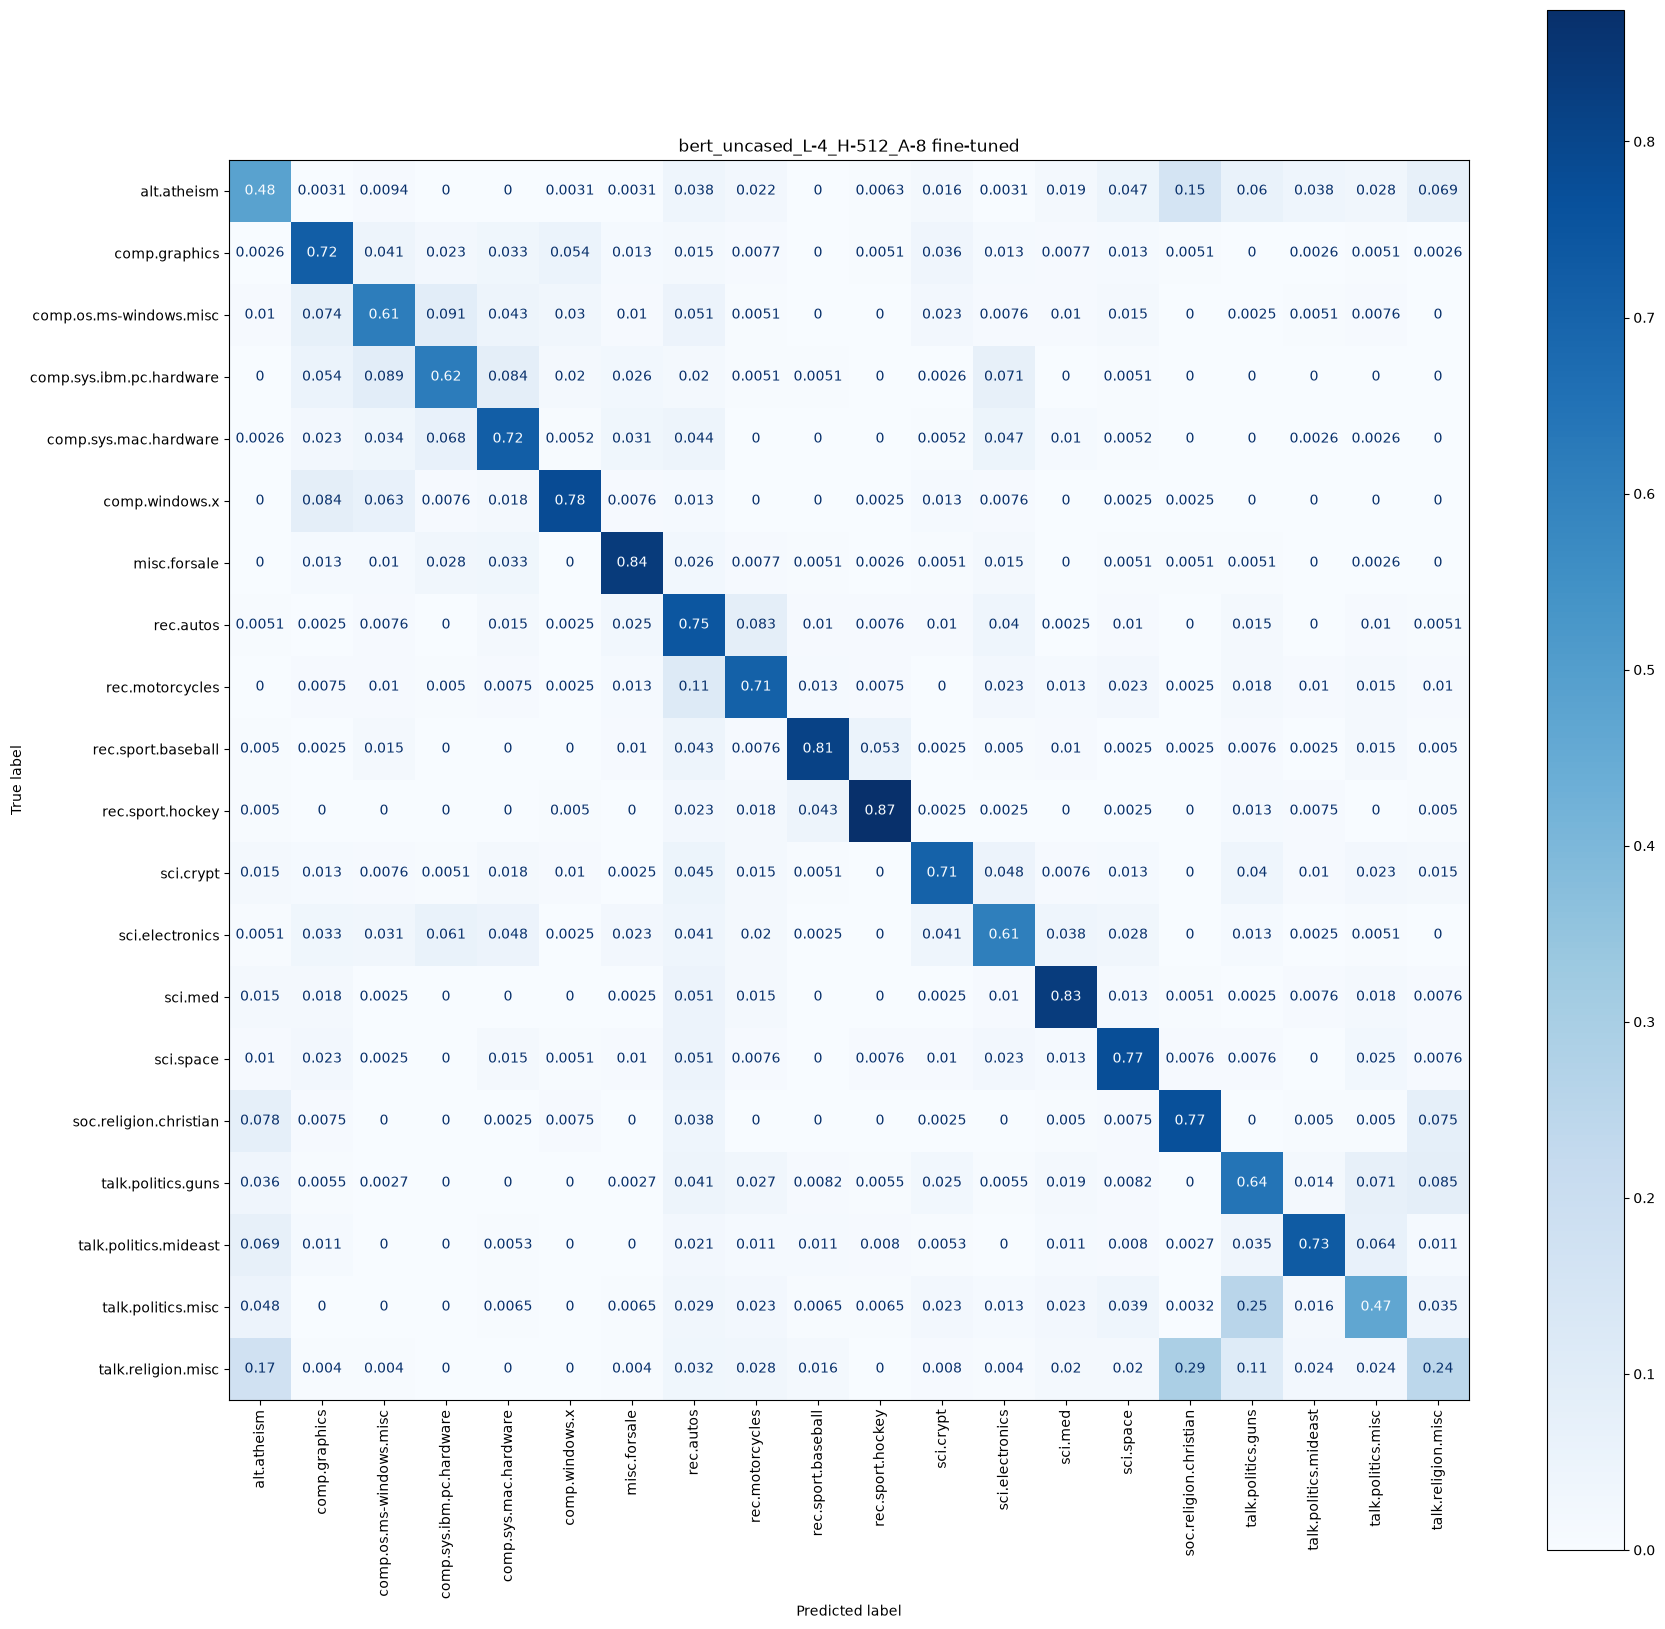

In [44]:
show_results(f'{FT_NAME.split("/")[-1]} fine-tuned', x_valid['class'], preds)

## Where it went next: ModernBERT (2024)
Encoders kept improving after BERT. **ModernBERT** (Answer.AI and LightOn, Dec 2024) was trained on far more text, including code,
and reads up to **8,192 tokens** instead of BERT's 512. That matters here: the 90th-percentile post is about 400 *words*,
and BERT had to cut long posts off at the limit.

The fine-tuning code above needs no changes. Edit the first lines of the fine-tuning cell, rerun it and the results cell:
```python
FT_NAME = "answerdotai/ModernBERT-base"; LR = 5e-5; BATCH = 16
MAX_LEN, EPOCHS = 512, 4     # try 1024 if memory allows
```
(Requires `transformers >= 4.48`. On an 8 GB GPU you may need `BATCH = 8` at 512 tokens.)

Paper: https://arxiv.org/abs/2412.13663

The other major change since 2018 is large decoder models (GPT-style LLMs) that can classify text from a prompt with no training at all.
For a fixed label set and 11k labeled examples, a fine-tuned encoder is still very hard to beat on accuracy per dollar.

## The scoreboard

GRU (learned embeddings)                   0.446
Naive Bayes (bag of words)                 0.543
BERT frozen features + dense               0.598
Universal Sentence Encoder + dense (TF)    0.656
Distilled USE + dense (PyTorch)            0.658
bert_uncased_L-4_H-512_A-8 fine-tuned      0.697


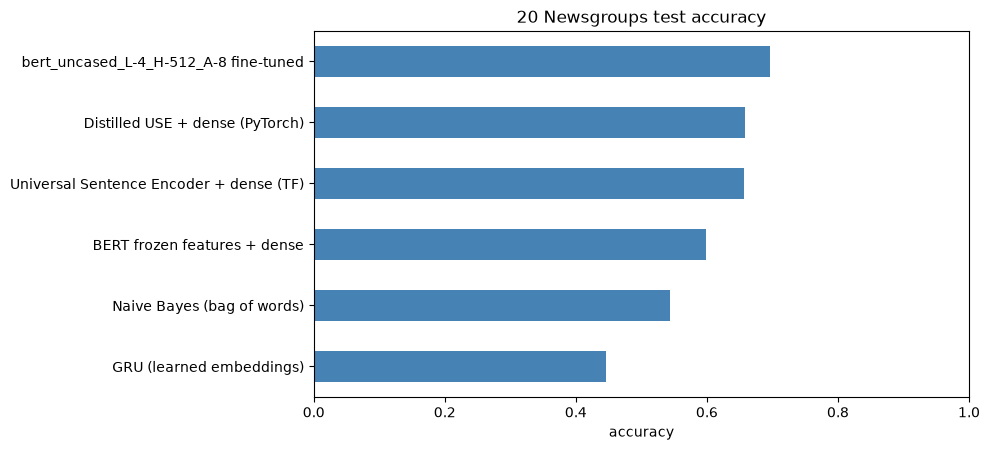

In [48]:
scores = pd.Series(results).sort_values()
print(scores.round(3).to_string())
plt.rcParams["figure.figsize"] = (10, 0.6 * len(scores) + 1)
scores.plot.barh(color='steelblue', xlim=(0, 1), title='20 Newsgroups test accuracy')
plt.xlabel('accuracy')
plt.tight_layout()
plt.show()

## Discussion
Well our GRU was underperorming, beat even by a BOW model and Naive bayes.  How did that happen.  Because this was written as a lightning fast intro for my survery classes, a lot goes unsaid.  When I was refining this in 2026 it immediately drew a red flag "That ain't right" and the problem is the RNN/GRU use my personal tokenizer that was pretty unrefined.  Lets take the time to fix that now and see what effect it has on performance

In [ ]:
# the offending piece
word_counts = Counter()

for i in range(X_train['message'].shape[0]):
    tmp = X_train.iloc[i,0].lower().split(" ")
    for i in tmp:
        word_counts[i] += 1

extra = Counter({"<pad>":10000001,"<unk>":1000000})
word_counts = word_counts + extra

In [54]:
import string
cleaned = X_train['message'][0].translate(str.maketrans("", "", string.punctuation))
tmp = cleaned.lower()

In [58]:
print(cleaned)
print("------")
print(tmp)

I was wondering if anyone out there could enlighten me on this car I saw the other day It was a 2door sports car looked to be from the late 60s early 70s It was called a Bricklin The doors were really small In addition the front bumper was separate from the rest of the body This is  all I know If anyone can tellme a model name engine specs years of production where this car is made history or whatever info you have on this funky looking car please email
------
i was wondering if anyone out there could enlighten me on this car i saw the other day it was a 2door sports car looked to be from the late 60s early 70s it was called a bricklin the doors were really small in addition the front bumper was separate from the rest of the body this is  all i know if anyone can tellme a model name engine specs years of production where this car is made history or whatever info you have on this funky looking car please email


In [65]:
Old_word_counts = Counter()
New_word_counts = Counter()
for i in range(X_train['message'].shape[0]):
    tmp = X_train.iloc[i,0].lower().split(" ")
    for i in tmp:
        Old_word_counts[i] += 1

extra = Counter({"<pad>":10000001,"<unk>":1000000})
Old_word_counts = Old_word_counts + extra

In [66]:
for i in range(X_train['message'].shape[0]):
    cleaned = X_train.iloc[i,0].translate(str.maketrans("", "", string.punctuation))
    tmp = cleaned.lower().split(" ")
    for i in tmp:
        New_word_counts[i] += 1

extra = Counter({"<pad>":10000001,"<unk>":1000000})
New_word_counts = New_word_counts + extra

In [67]:
print(len(Old_word_counts))
print(len(New_word_counts))

196250
113105


In [68]:
words = New_word_counts.most_common(5000)
words

[('<pad>', 10000001),
 ('<unk>', 1000000),
 ('', 572932),
 ('the', 105626),
 ('to', 52716),
 ('of', 46746),
 ('a', 42842),
 ('and', 42150),
 ('in', 30662),
 ('is', 30242),
 ('i', 28462),
 ('that', 26888),
 ('it', 20815),
 ('for', 19822),
 ('you', 16828),
 ('this', 14340),
 ('on', 14204),
 ('be', 13741),
 ('are', 12974),
 ('have', 12814),
 ('with', 12606),
 ('not', 12472),
 ('as', 11297),
 ('or', 10301),
 ('was', 9545),
 ('but', 9487),
 ('if', 9397),
 ('they', 8747),
 ('from', 8235),
 ('by', 8096),
 ('at', 7709),
 ('an', 7231),
 ('can', 6820),
 ('will', 6632),
 ('all', 6327),
 ('my', 6218),
 ('what', 6196),
 ('there', 6190),
 ('would', 6127),
 ('one', 6115),
 ('do', 5757),
 ('about', 5714),
 ('he', 5693),
 ('we', 5660),
 ('has', 5402),
 ('your', 5276),
 ('so', 5208),
 ('\t', 4973),
 ('no', 4861),
 ('some', 4787),
 ('any', 4772),
 ('which', 4607),
 ('me', 4505),
 ('1', 4444),
 ('were', 4408),
 ('who', 4363),
 ('its', 4275),
 ('out', 4240),
 ('more', 4065),
 ('x', 3988),
 ('people', 3987)

In [69]:
lookup = {}
rev_lookup = {}
for i,j in enumerate(words):
    lookup[j[0]]=i
    rev_lookup[i] = j[0]

In [70]:
print(make_seq(X_train['message'][0]))
check = make_seq(X_train['message'][0])
" ".join([rev_lookup[i] for i in check])

[10, 24, 1232, 26, 131, 57, 37, 89, 1, 52, 16, 15, 270, 10, 508, 3, 64, 1, 12, 24, 6, 1, 2370, 1, 890, 4, 17, 28, 3, 1115, 1, 665, 1, 12, 24, 256, 6, 1, 3, 3316, 54, 142, 1, 8, 1, 3, 746, 1, 24, 1448, 28, 3, 612, 5, 3, 1, 15, 9, 2, 34, 10, 1, 26, 131, 32, 1, 6, 657, 1, 891, 1, 144, 5, 1, 115, 15, 270, 9, 1, 1, 23, 659, 374, 14, 19, 16, 15, 1, 304, 1, 138, 1]


'i was wondering if anyone out there could <unk> me on this car i saw the other <unk> it was a <unk> sports <unk> looked to be from the late <unk> early <unk> it was called a <unk> the doors were really <unk> in <unk> the front <unk> was separate from the rest of the <unk> this is  all i <unk> if anyone can <unk> a model <unk> engine <unk> years of <unk> where this car is <unk> <unk> or whatever info you have on this <unk> looking <unk> please <unk>'

In [71]:
max_length = 400 # not precisily 90th percentile, but we love even numbers
# default pad is 0, not everyone uses default--its a hidden GOTCHA!
# But I used default
X_train_data = sequence.pad_sequences(X_train['sequence'], maxlen=max_length)
x_valid_data = sequence.pad_sequences(x_valid['sequence'], maxlen=max_length)

In [72]:
X_train_data[0]

array([   0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,   

In [73]:
from tensorflow.keras import Input
# create the model
es = EarlyStopping(patience=5, restore_best_weights=True)
vector_size = 101 #even numbers are for losers!
model = Sequential()
model.add(Input(shape=(max_length,)))  # Keras 3: input_length on Embedding is gone, declare the input instead
model.add(Embedding(5000, vector_size))
model.add(GRU(100)) #I started with LSTM for speed, but GRU gave better results.  No Free Lunch!
model.add(Dropout(0.30)) #this thing overtrains hard, so Dropout is your regularization in NN
model.add(Dense(500,activation='relu'))
model.add(Dropout(0.30))
model.add(Dense(20, activation='softmax'))
#I threw in the top k accuracy to show that while results aren't great, it is getting things mostly right
# annd just confusing similar tasks.
model.compile(loss='sparse_categorical_crossentropy', optimizer='rmsprop', metrics=['accuracy','sparse_top_k_categorical_accuracy'])
model.summary()
model.fit(X_train_data, X_train['class'], validation_data=(x_valid_data, x_valid['class']),
          epochs=300, batch_size=64, callbacks=[es])

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 400, 101)       │       505,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_2 (GRU)                     │ (None, 100)            │        60,900 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 500)            │        50,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 500)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 20)             │        10,020 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 626,420 (2.39 MB)

 Trainable params: 626,420 (2.39 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/300
177/177 ━━━━━━━━━━━━━━━━━━━━ 12s 58ms/step - accuracy: 0.0635 - loss: 2.9871 - sparse_top_k_categorical_accuracy: 0.2792 - val_accuracy: 0.0701 - val_loss: 2.9783 - val_sparse_top_k_categorical_accuracy: 0.2985
Epoch 2/300
177/177 ━━━━━━━━━━━━━━━━━━━━ 10s 57ms/step - accuracy: 0.0907 - loss: 2.9179 - sparse_top_k_categorical_accuracy: 0.3543 - val_accuracy: 0.1062 - val_loss: 2.8434 - val_sparse_top_k_categorical_accuracy: 0.4022
Epoch 3/300
177/177 ━━━━━━━━━━━━━━━━━━━━ 13s 75ms/step - accuracy: 0.1295 - loss: 2.7137 - sparse_top_k_categorical_accuracy: 0.4828 - val_accuracy: 0.1325 - val_loss: 2.6637 - val_sparse_top_k_categorical_accuracy: 0.5003
Epoch 4/300
177/177 ━━━━━━━━━━━━━━━━━━━━ 9s 52ms/step - accuracy: 0.1680 - loss: 2.5514 - sparse_top_k_categorical_accuracy: 0.5653 - val_accuracy: 0.1714 - val_loss: 2.5313 - val_sparse_top_k_categorical_accuracy: 0.5747
Epoch 5/300
177/177 ━━━━━━━━━━━━━━━━━━━━ 9s 53ms/step - accuracy: 0.2196 - loss: 2.3567 - sparse_top_k_catego

In [74]:
#Lets try larger Vectors
from tensorflow.keras import Input
# create the model
es = EarlyStopping(patience=5, restore_best_weights=True)
vector_size = 600 #diminishing returns over 300--even LLM are 1-2k only!
model = Sequential()
model.add(Input(shape=(max_length,)))  # Keras 3: input_length on Embedding is gone, declare the input instead
model.add(Embedding(5000, vector_size))
model.add(GRU(100)) #I started with LSTM for speed, but GRU gave better results.  No Free Lunch!
model.add(Dropout(0.30)) #this thing overtrains hard, so Dropout is your regularization in NN
model.add(Dense(500,activation='relu'))
model.add(Dropout(0.30))
model.add(Dense(20, activation='softmax'))
#I threw in the top k accuracy to show that while results aren't great, it is getting things mostly right
# annd just confusing similar tasks.
model.compile(loss='sparse_categorical_crossentropy', optimizer='rmsprop', metrics=['accuracy','sparse_top_k_categorical_accuracy'])
model.summary()
model.fit(X_train_data, X_train['class'], validation_data=(x_valid_data, x_valid['class']),
          epochs=300, batch_size=64, callbacks=[es])

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 400, 600)       │     3,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_3 (GRU)                     │ (None, 100)            │       210,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 500)            │        50,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 500)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 20)             │        10,020 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,271,120 (12.48 MB)

 Trainable params: 3,271,120 (12.48 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/300
177/177 ━━━━━━━━━━━━━━━━━━━━ 12s 60ms/step - accuracy: 0.0685 - loss: 2.9766 - sparse_top_k_categorical_accuracy: 0.2948 - val_accuracy: 0.0737 - val_loss: 2.9566 - val_sparse_top_k_categorical_accuracy: 0.3229
Epoch 2/300
177/177 ━━━━━━━━━━━━━━━━━━━━ 10s 59ms/step - accuracy: 0.1072 - loss: 2.8580 - sparse_top_k_categorical_accuracy: 0.4019 - val_accuracy: 0.1356 - val_loss: 2.7427 - val_sparse_top_k_categorical_accuracy: 0.4774
Epoch 3/300
177/177 ━━━━━━━━━━━━━━━━━━━━ 13s 73ms/step - accuracy: 0.1482 - loss: 2.6831 - sparse_top_k_categorical_accuracy: 0.5086 - val_accuracy: 0.1130 - val_loss: 2.8174 - val_sparse_top_k_categorical_accuracy: 0.4579
Epoch 4/300
177/177 ━━━━━━━━━━━━━━━━━━━━ 10s 57ms/step - accuracy: 0.1906 - loss: 2.4828 - sparse_top_k_categorical_accuracy: 0.6107 - val_accuracy: 0.2031 - val_loss: 2.4466 - val_sparse_top_k_categorical_accuracy: 0.6083
Epoch 5/300
177/177 ━━━━━━━━━━━━━━━━━━━━ 10s 58ms/step - accuracy: 0.2339 - loss: 2.3125 - sparse_top_k_cate

In [ ]:
# How about more Vocab!
words = New_word_counts.most_common(40000)
lookup = {}
rev_lookup = {}
for i,j in enumerate(words):
    lookup[j[0]]=i
    rev_lookup[i] = j[0]

#Lets try larger Vectors
from tensorflow.keras import Input
# create the model
es = EarlyStopping(patience=5, restore_best_weights=True)
vector_size = 600 #diminishing returns over 300--even LLM are 1-2k only!
model = Sequential()
model.add(Input(shape=(max_length,)))  # Keras 3: input_length on Embedding is gone, declare the input instead
model.add(Embedding(20000, vector_size))
model.add(GRU(500)) #I started with LSTM for speed, but GRU gave better results.  No Free Lunch!
model.add(Dropout(0.30)) #this thing overtrains hard, so Dropout is your regularization in NN
model.add(Dense(500,activation='relu'))
model.add(Dropout(0.30))
model.add(Dense(20, activation='softmax'))
#I threw in the top k accuracy to show that while results aren't great, it is getting things mostly right
# annd just confusing similar tasks.
model.compile(loss='sparse_categorical_crossentropy', optimizer='rmsprop', metrics=['accuracy','sparse_top_k_categorical_accuracy'])
model.summary()
model.fit(X_train_data, X_train['class'], validation_data=(x_valid_data, x_valid['class']),
          epochs=300, batch_size=64, callbacks=[es])

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_9 (Embedding)         │ (None, 400, 600)       │    12,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_9 (GRU)                     │ (None, 500)            │     1,653,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_18 (Dropout)            │ (None, 500)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 500)            │       250,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_19 (Dropout)            │ (None, 500)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 20)             │        10,020 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,913,520 (53.08 MB)

 Trainable params: 13,913,520 (53.08 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/300
177/177 ━━━━━━━━━━━━━━━━━━━━ 164s 925ms/step - accuracy: 0.0740 - loss: 2.9753 - sparse_top_k_categorical_accuracy: 0.2946 - val_accuracy: 0.0749 - val_loss: 2.9513 - val_sparse_top_k_categorical_accuracy: 0.3334
Epoch 2/300
 10/177 ━━━━━━━━━━━━━━━━━━━━ 2:00 724ms/step - accuracy: 0.0922 - loss: 2.9157 - sparse_top_k_categorical_accuracy: 0.3328

(11314, 3)